# Hybrid IDS Framework (final, Kaggle version, run 2 of 2: CICIDS2017) — NSL-KDD + CICIDS2017

| Stage | Model | Task |
|---|---|---|
| 1 | CNN-GRU + Attention | Binary detection (Normal vs Attack) |
| 2 | XGBoost | Attack-type classification (samples flagged by Stage 1) |
| 3 | Autoencoder | Unknown / zero-day detection (samples Stage 1 calls Normal); low-confidence Stage 2 output → `Unknown` |

### Evaluation protocol
1. **No test-set leakage**: all thresholds (Stage 1 decision threshold, Autoencoder threshold) are chosen on a **validation split**; test sets are used only for reporting.
2. **SMOTE on the training split only**; the Autoencoder is trained on real normal traffic only.
3. **NSL-KDD**: train on KDDTrain+, report on the official **KDDTest+** (plus an in-distribution hold-out). Encoders/scalers are fit on the training split only.
4. **CICIDS2017**: NaN/Inf, exact duplicates and conflicting-label duplicates removed; one shared stratified train/val/test split.
5. **End-to-end hybrid evaluation**, with three views: binary, strict multiclass, and **detection-aware** (an attack labelled `Unknown` counts as detected).
6. **Zero-day**: NSL-KDD — the attack types present in KDDTest+ but absent from KDDTrain+; CICIDS2017 — leave-one-attack-out.
7. **FAR vs zero-day trade-off curve** over Autoencoder thresholds (all thresholds derived from validation data; the reported operating point is fixed in advance by `AE_FPR_BUDGET`).
8. **Paper evidence**: classical and deep baselines on identical splits, architecture and pipeline ablations, multiple seeds (mean ± std), McNemar tests, SHAP, computational cost.

### Running on Kaggle
1. **Settings** (right panel): **Accelerator → GPU T4 x2**, **Internet → On**.
2. **Add Input** (right panel): search and add the NSL-KDD dataset (e.g. `hassan06/nslkdd`). For CICIDS2017, upload your `Clean_CICIDS2017.csv` as a private dataset (**Add Input → Upload → New Dataset**) and add it. The notebook finds the files automatically under `/kaggle/input`.
3. For long runs use **Save Version → Save & Run All (Commit)**: it runs in the background (up to 12 h, the browser can be closed) and keeps every output. Results appear in the version's **Output** tab, also as one zip file.
4. This notebook is preset for **run 2 of 2: CICIDS2017**. Expected time on a T4: ~6-8 h.


In [1]:
!pip install -q imbalanced-learn xgboost shap

In [2]:
import os, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix, classification_report)

# =========================== CONFIGURATION ===========================
DATASETS_TO_RUN   = ['CICIDS2017']   # preset for this notebook -- no change needed
RUN_PART_C        = True      # baselines, ablation, seeds, McNemar, SHAP
INPUT_ROOT        = '/kaggle/input'   # where Kaggle mounts added datasets
KDD_TRAIN_PATH    = None     # None = find automatically, or e.g. '/kaggle/input/nslkdd/KDDTrain+.txt'
KDD_TEST_PATH     = None
CIC_PATH          = None

SEED              = 42
EPOCHS_STAGE1     = 50        # early stopping on validation loss
EPOCHS_AE         = 100
EPOCHS_STAGE1_CIC = 20        # CICIDS is ~20x larger; its Stage 1 early-stops around 15-20 epochs anyway
EPOCHS_ZERO_DAY   = 10        # Stage 1 retraining in CICIDS leave-one-attack-out runs
# Baselines / ablations always get the same epoch budget as the proposed model on that dataset (fair comparison)
CIC_ARCH_ABLATION = False     # architecture ablation on CICIDS (~4 extra GPU hours); NSL-KDD always runs it
BATCH_KDD         = 256
BATCH_CIC         = 1024
USE_SMOTE         = True
AE_FPR_BUDGET     = 0.02      # operating point: AE threshold = 98th percentile of VALIDATION normal errors
AE_BUDGET_GRID    = [0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.10]   # trade-off curve
CONF_T            = 0.50      # Stage 2 max-probability below this -> 'Unknown'
SMOTE_TARGET_KDD  = 5000
SMOTE_TARGET_CIC  = 2000
CIC_MIN_CLASS     = 20        # CICIDS classes with fewer samples (after dedup) are dropped
CIC_ZERO_DAY_CLASSES = None   # None = 3 attack classes chosen automatically, or a list of labels
SEEDS_KDD         = [42, 7, 123, 2024, 99]   # the seed equal to SEED reuses the main run
SEEDS_CIC         = [42, 7]
CIC_LOAO_BASELINES = True    # also retrain XGBoost and GRU baselines without the held-out attack
KDD_EXPECTED_ROWS = {'train': 125973, 'test': 22544}
# =====================================================================

MAIN_SEED = SEED
random.seed(SEED); np.random.seed(SEED)
RESULTS, COSTS, BASE_COSTS, ZERO_DAY, SEED_RUNS, MCNEMAR = [], [], [], [], [], []
PREDS, SCORES, TABLES, RUNS = {}, {}, {}, {}

BASE_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
OUT_DIR = os.path.join(BASE_DIR, 'run_' + '_'.join(d.replace('-', '') for d in DATASETS_TO_RUN))
os.makedirs(OUT_DIR, exist_ok=True)
out = lambda name: os.path.join(OUT_DIR, name)
print('Outputs ->', os.path.abspath(OUT_DIR))

plt.rcParams.update({'font.size': 11, 'axes.titlesize': 12, 'axes.labelsize': 11,
                     'legend.fontsize': 10, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
                     'axes.grid': True, 'grid.alpha': 0.3, 'savefig.dpi': 300})

Outputs -> /kaggle/working/run_CICIDS2017


In [3]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Conv1D, GRU, LSTM, Dense, Dropout, BatchNormalization,
    GlobalAveragePooling1D, Multiply, Permute, Activation, Flatten, RepeatVector)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

tf.keras.utils.set_random_seed(SEED)
GPU = len(tf.config.list_physical_devices('GPU')) > 0
XGB_DEVICE = 'cuda' if GPU else 'cpu'
print(f'TF {tf.__version__} | GPU: {GPU}')

TF 2.20.0 | GPU: True


## Helpers — metrics, logging, saving

In [4]:
def upsert(lst, row, keys):
    """Insert row, replacing any earlier row with the same keys (re-running a cell never duplicates)."""
    lst[:] = [r for r in lst if any(r.get(k) != row.get(k) for k in keys)]
    lst.append(row)

def bin_metrics(y, pred, score=None):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    d = dict(Acc=accuracy_score(y, pred),
             Prec=precision_score(y, pred, zero_division=0),
             Rec=recall_score(y, pred, zero_division=0),
             F1=f1_score(y, pred, zero_division=0),
             FAR=fp / (fp + tn) if (fp + tn) else np.nan,
             MCC=matthews_corrcoef(y, pred))
    if score is not None and len(np.unique(y)) == 2:
        d['AUC'] = roc_auc_score(y, score)
    return d

def multi_metrics(y, pred, labels=None):
    """labels = the true classes; a predicted 'Unknown' counts as an error but is not a class of its own."""
    y, pred = np.asarray(y).astype(str), np.asarray(pred).astype(str)
    labels = sorted(set(y)) if labels is None else list(labels)
    return dict(Acc=accuracy_score(y, pred),
                MacroF1=f1_score(y, pred, labels=labels, average='macro', zero_division=0),
                WeightedF1=f1_score(y, pred, labels=labels, average='weighted', zero_division=0),
                MCC=matthews_corrcoef(y, pred))

def detection_aware(c, out_, normal):
    """An attack predicted as its true class OR as 'Unknown' is a correct detection."""
    c, out_ = np.asarray(c).astype(str), np.asarray(out_).astype(str)
    att, unk = c != normal, out_ == 'Unknown'
    correct = np.where(att, (out_ == c) | unk, out_ == normal)
    return dict(DA_Acc=correct.mean(),
                DetRate=(att & (out_ != normal)).sum() / max(att.sum(), 1),
                ExactType=(att & (out_ == c)).sum() / max(att.sum(), 1),
                UnknownShare=(att & unk).sum() / max(att.sum(), 1),
                UnknownPrec=(att & unk).sum() / max(unk.sum(), 1))

def log(dataset, model, split, d):
    upsert(RESULTS, {'Dataset': dataset, 'Model': model, 'Split': split,
                     **{k: round(float(v), 4) for k, v in d.items()}}, ['Dataset', 'Model', 'Split'])
    print(f'  [{dataset} | {split}] {model}: ' +
          ' '.join(f'{k}={v*100:.2f}%' if k != 'AUC' else f'{k}={v:.4f}' for k, v in d.items()))

def add_zero_day(dataset, unseen, model, det, unseen_mask, normal_mask):
    upsert(ZERO_DAY, {'Dataset': dataset, 'Unseen attack': unseen, 'Model': model,
                      'n': int(unseen_mask.sum()),
                      'Detection rate': round(float(det[unseen_mask].mean()), 4),
                      'FAR on normal': round(float(det[normal_mask].mean()), 4)},
           ['Dataset', 'Unseen attack', 'Model'])

def best_f1_threshold(y, score):
    p, r, t = precision_recall_curve(y, score)
    f1 = 2 * p * r / (p + r + 1e-12)
    return float(t[np.argmax(f1[:-1])])

def save_all():
    pd.DataFrame(RESULTS).to_csv(out('results_all.csv'), index=False)
    pd.DataFrame(ZERO_DAY).to_csv(out('results_zero_day.csv'), index=False)
    pd.DataFrame(COSTS).to_csv(out('results_cost_proposed.csv'), index=False)
    pd.DataFrame(BASE_COSTS).to_csv(out('results_cost_baselines.csv'), index=False)
    if SEED_RUNS: pd.DataFrame(SEED_RUNS).to_csv(out('results_seeds_raw.csv'), index=False)
    if MCNEMAR:   pd.DataFrame(MCNEMAR).to_csv(out('results_mcnemar.csv'), index=False)
    for k, t in TABLES.items():
        t.to_csv(out(f'{k}.csv'), index=False)

def savefig(name):
    plt.savefig(out(name + '.png'), dpi=300, bbox_inches='tight')
    plt.savefig(out(name + '.pdf'), bbox_inches='tight')

## Models — Stage 1 (CNN-GRU + Attention), Stage 2 (XGBoost), Stage 3 (Autoencoder)

In [5]:
def attention_block(x):
    a = Dense(1, activation='tanh')(x)
    a = Flatten()(a)
    a = Activation('softmax')(a)
    a = RepeatVector(x.shape[-1])(a)
    a = Permute([2, 1])(a)
    return Multiply()([x, a])

def build_seq(input_shape, arch='proposed'):
    """proposed = CNN + GRU + Attention.  Ablations: no_attention, no_cnn, no_gru.  Baselines: cnn, lstm, gru."""
    use_cnn  = arch in ('proposed', 'no_attention', 'no_gru', 'cnn')
    use_gru  = arch in ('proposed', 'no_attention', 'no_cnn', 'gru')
    use_attn = arch in ('proposed', 'no_cnn', 'no_gru')
    inp = Input(shape=input_shape); x = inp
    if use_cnn:
        x = Conv1D(64, 3, padding='same', activation='relu')(x)
        x = BatchNormalization()(x); x = Dropout(0.2)(x)
        x = Conv1D(128, 3, padding='same', activation='relu')(x)
        x = BatchNormalization()(x); x = Dropout(0.2)(x)
    if use_gru:
        x = GRU(128, return_sequences=True)(x)
        x = BatchNormalization()(x); x = Dropout(0.3)(x)
        x = GRU(64, return_sequences=True)(x)
    if arch == 'lstm':
        x = LSTM(128, return_sequences=True)(x)
        x = BatchNormalization()(x); x = Dropout(0.3)(x)
        x = LSTM(64, return_sequences=True)(x)
    if use_attn:
        x = attention_block(x)
    x = GlobalAveragePooling1D()(x)
    x = Dense(128, activation='relu')(x)
    x = BatchNormalization()(x); x = Dropout(0.3)(x)
    x = Dense(64, activation='relu')(x); x = Dropout(0.2)(x)
    out_ = Dense(1, activation='sigmoid')(x)
    m = Model(inp, out_)
    m.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
    return m

def build_ae(dim):
    inp = Input(shape=(dim,))
    x = Dense(256, activation='relu')(inp); x = BatchNormalization()(x); x = Dropout(0.1)(x)
    x = Dense(128, activation='relu')(x);   x = BatchNormalization()(x); x = Dropout(0.1)(x)
    x = Dense(64, activation='relu')(x);    x = BatchNormalization()(x)
    enc = Dense(32, activation='relu')(x)
    x = Dense(64, activation='relu')(enc);  x = BatchNormalization()(x)
    x = Dense(128, activation='relu')(x);   x = BatchNormalization()(x)
    x = Dense(256, activation='relu')(x)
    dec = Dense(dim, activation='linear')(x)
    ae = Model(inp, dec); ae.compile(optimizer=Adam(1e-3), loss='mse')
    return ae

def smote_binary(X, y):
    if not USE_SMOTE:
        return X, y
    return SMOTE(random_state=SEED).fit_resample(X, y)

def smote_multi(X, y, target):
    u, c = np.unique(y, return_counts=True)
    strat = {int(k): target for k, v in zip(u, c) if 1 < v < target}
    if not USE_SMOTE or not strat:
        return X, y
    k = max(1, min(5, min(c[np.isin(u, list(strat))]) - 1))
    return SMOTE(sampling_strategy=strat, k_neighbors=k, random_state=SEED).fit_resample(X, y)


class Stage1:
    """CNN-GRU + Attention binary detector. Decision threshold = max F1 on validation."""
    def __init__(self, epochs, batch, arch='proposed'):
        self.epochs, self.batch, self.arch = epochs, batch, arch
    def fit(self, Xtr, ytr, Xval, yval):
        t0 = time.time()
        tf.keras.utils.set_random_seed(SEED)
        Xs, ys = smote_binary(Xtr, ytr)
        cw = None
        if not USE_SMOTE:
            w = compute_class_weight('balanced', classes=np.array([0, 1]), y=ys)
            cw = {0: float(w[0]), 1: float(w[1])}
        self.model = build_seq((Xs.shape[1], 1), self.arch)
        self.history = self.model.fit(
            Xs[..., None], ys, validation_data=(Xval[..., None], yval),
            epochs=self.epochs, batch_size=self.batch, class_weight=cw, verbose=2,
            callbacks=[EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
                       ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)])
        self.threshold = best_f1_threshold(yval, self.predict_proba(Xval))
        self.train_time = time.time() - t0
        self.n_params = self.model.count_params()
        return self
    def predict_proba(self, X):
        return self.model.predict(X[..., None], batch_size=4096, verbose=0).ravel()
    def predict(self, X):
        return (self.predict_proba(X) >= self.threshold).astype(int)


class Stage2:
    """XGBoost attack-type classifier, trained on attack samples only (early stopping on validation)."""
    def fit(self, Xtr, ctr, Xval, cval, smote_target):
        t0 = time.time()
        self.le = LabelEncoder().fit(ctr)
        ytr = self.le.transform(ctr)
        m = np.isin(cval, self.le.classes_)
        Xv, yv = Xval[m], self.le.transform(cval[m])
        Xs, ys = smote_multi(Xtr, ytr, smote_target)
        k = len(self.le.classes_)
        self.model = XGBClassifier(
            n_estimators=1000, max_depth=8, learning_rate=0.1, subsample=0.8,
            colsample_bytree=0.8, eval_metric='mlogloss' if k > 2 else 'logloss',
            early_stopping_rounds=30, tree_method='hist', device=XGB_DEVICE,
            random_state=SEED, n_jobs=-1, verbosity=0)
        self.model.fit(Xs, ys, eval_set=[(Xv, yv)], verbose=False)
        self.train_time = time.time() - t0
        return self
    def predict_proba(self, X):
        return self.model.predict_proba(X)
    def predict(self, X):
        return self.le.inverse_transform(self.predict_proba(X).argmax(1))


class Stage3:
    """Autoencoder trained on REAL normal traffic; threshold from validation normals."""
    def __init__(self, epochs, batch):
        self.epochs, self.batch = epochs, batch
    def fit(self, Xn_tr, Xn_val):
        t0 = time.time()
        tf.keras.utils.set_random_seed(SEED)
        self.model = build_ae(Xn_tr.shape[1])
        self.model.fit(Xn_tr, Xn_tr, validation_data=(Xn_val, Xn_val),
                       epochs=self.epochs, batch_size=self.batch, verbose=2,
                       callbacks=[EarlyStopping(monitor='val_loss', patience=10,
                                                restore_best_weights=True)])
        self.val_scores = self.score(Xn_val)
        self.threshold = float(np.quantile(self.val_scores, 1 - AE_FPR_BUDGET))
        self.train_time = time.time() - t0
        self.n_params = self.model.count_params()
        return self
    def score(self, X):
        return np.mean((X - self.model.predict(X, batch_size=4096, verbose=0)) ** 2, axis=1)
    def predict(self, X):
        return (self.score(X) > self.threshold).astype(int)

## Hybrid pipeline, evaluation and paper figures (shared by both datasets)

Decision logic per sample:
1. Stage 1 says **Attack** → Stage 2 assigns the attack type; if Stage 2's highest probability is below `CONF_T` → **Unknown**.
2. Stage 1 says **Normal** → Stage 3 reconstruction error above its validation threshold → **Unknown**, otherwise **Normal**.

In [6]:
def hybrid_predict(s1, s2, s3, X, normal, use_ae=True, conf_t=None, p1=None, e3=None, ae_thr=None):
    conf_t = CONF_T if conf_t is None else conf_t
    ae_thr = s3.threshold if ae_thr is None else ae_thr
    p1 = s1.predict_proba(X) if p1 is None else p1
    att = p1 >= s1.threshold
    out_ = np.full(len(X), normal, dtype=object)
    if att.any():
        proba = s2.predict_proba(X[att])
        cls = s2.le.inverse_transform(proba.argmax(1)).astype(object)
        cls[proba.max(1) < conf_t] = 'Unknown'
        out_[att] = cls
    if use_ae and (~att).any():
        idx = np.where(~att)[0]
        e = s3.score(X[idx]) if e3 is None else e3[idx]
        out_[idx[e > ae_thr]] = 'Unknown'
    return out_, p1


def run_pipeline(name, D, normal, smote_target, batch, epochs1=EPOCHS_STAGE1, s3=None, evaluate=True):
    """D: dict with Xtr, ctr, Xval, cval (category names) and tests={split: (X, c)}."""
    ytr, yval = (D['ctr'] != normal).astype(int), (D['cval'] != normal).astype(int)
    print(f'\n=== {name}: Stage 1 (CNN-GRU+Attn) ===')
    s1 = Stage1(epochs1, batch).fit(D['Xtr'], ytr, D['Xval'], yval)
    print(f'  validation threshold = {s1.threshold:.4f}')

    print(f'=== {name}: Stage 2 (XGBoost, attacks only) ===')
    a_tr, a_val = ytr == 1, yval == 1
    s2 = Stage2().fit(D['Xtr'][a_tr], D['ctr'][a_tr], D['Xval'][a_val], D['cval'][a_val], smote_target)
    print(f'  classes = {list(s2.le.classes_)}')

    if s3 is None:
        print(f'=== {name}: Stage 3 (Autoencoder, normal traffic only) ===')
        s3 = Stage3(EPOCHS_AE, batch).fit(D['Xtr'][ytr == 0], D['Xval'][yval == 0])
        print(f'  validation threshold = {s3.threshold:.6f}')

    run = dict(s1=s1, s2=s2, s3=s3, preds={})
    if evaluate:
        for split, (X, c) in D['tests'].items():
            run['preds'][split] = evaluate_split(name, split, s1, s2, s3, X, c, normal)
        record_costs(name, s1, s2, s3, D['tests'][list(D['tests'])[-1]][0])
        save_all()
    return run


def evaluate_split(name, split, s1, s2, s3, X, c, normal):
    y = (c != normal).astype(int)
    true_labels = sorted(set(c.astype(str)))
    p1 = s1.predict_proba(X)
    e3 = s3.score(X)
    log(name, 'Proposed: Stage 1 CNN-GRU+Attn', split,
        bin_metrics(y, (p1 >= s1.threshold).astype(int), p1))
    known = (y == 1) & np.isin(c, s2.le.classes_)
    pred2 = s2.predict(X[known])
    log(name, 'Proposed: Stage 2 XGBoost (known attacks)', split, multi_metrics(c[known], pred2))
    log(name, 'Proposed: Stage 3 Autoencoder', split,
        bin_metrics(y, (e3 > s3.threshold).astype(int), e3))
    out_, _ = hybrid_predict(s1, s2, s3, X, normal, p1=p1, e3=e3)
    log(name, 'Proposed: Hybrid (binary)', split, bin_metrics(y, (out_ != normal).astype(int)))
    log(name, 'Proposed: Hybrid (multiclass, strict)', split,
        multi_metrics(c, out_, labels=true_labels))
    log(name, 'Proposed: Hybrid (detection-aware)', split, detection_aware(c, out_, normal))
    return dict(y=y, c=c, p1=p1, e3=e3, out=out_, known=known, pred2=pred2)


def record_costs(name, s1, s2, s3, X):
    n = min(len(X), 10000); Xs = X[:n]
    t = time.time(); hybrid_predict(s1, s2, s3, Xs, 'x'); t_h = time.time() - t
    t = time.time(); s1.predict_proba(Xs); t_1 = time.time() - t
    bi = getattr(s2.model, 'best_iteration', None)
    upsert(COSTS, {'Dataset': name, 'Stage 1 params': s1.n_params, 'AE params': s3.n_params,
                   'XGB trees': int(bi + 1) if bi is not None else None,
                   'Train S1 (s)': round(s1.train_time, 1), 'Train S2 (s)': round(s2.train_time, 1),
                   'Train S3 (s)': round(s3.train_time, 1),
                   'Infer S1 (ms/sample)': round(1000 * t_1 / n, 4),
                   'Infer hybrid (ms/sample)': round(1000 * t_h / n, 4)}, ['Dataset'])


def print_reports(name, run, split, normal):
    P = run['preds'][split]
    true_labels = sorted(set(P['c'].astype(str)))
    print(f'Stage 2 (XGBoost) on {split}, attacks of known families:')
    print(classification_report(P['c'][P['known']], P['pred2'], digits=4, zero_division=0))
    print(f'Hybrid end-to-end on {split} (strict; Unknown counted as error):')
    print(classification_report(P['c'].astype(str), P['out'].astype(str), labels=true_labels,
                                digits=4, zero_division=0))


def per_class_detection(name, run, split, normal):
    """Per true class: how often Stage 1 / the hybrid raise an alarm, and how the hybrid labels it."""
    P = run['preds'][split]
    c, o = P['c'].astype(str), P['out'].astype(str)
    s1 = P['p1'] >= run['s1'].threshold
    rows = []
    for k in [normal] + sorted(set(c) - {normal}):
        m = c == k
        rows.append({'Class': k, 'n': int(m.sum()),
                     'Stage 1 alarm': round(float(s1[m].mean()), 4),
                     'Hybrid alarm': round(float((o[m] != normal).mean()), 4),
                     'Hybrid exact class': round(float((o[m] == k).mean()), 4),
                     'Hybrid Unknown': round(float((o[m] == 'Unknown').mean()), 4)})
    t = pd.DataFrame(rows)
    TABLES[f'{tag_of(name)}_per_class_detection'] = t
    print('Per-class alarm rates (for the normal class, "alarm" = false-alarm rate):')
    print(t.to_string(index=False))
    return t


def tradeoff_curve(name, run, D, split, normal, novel_mask=None):
    """Hybrid detection vs FAR for several AE thresholds, each taken from VALIDATION normal errors."""
    P = run['preds'][split]
    s3 = run['s3']
    att1 = P['p1'] >= run['s1'].threshold
    y = P['y']
    rows = []
    for b in AE_BUDGET_GRID:
        thr = float(np.quantile(s3.val_scores, 1 - b))
        det = att1 | (P['e3'] > thr)
        r = {'AE budget (val FPR)': b, 'Threshold': thr,
             'Detection rate': float(det[y == 1].mean()), 'FAR': float(det[y == 0].mean()),
             'Operating point': np.isclose(b, AE_FPR_BUDGET)}
        if novel_mask is not None:
            r['Zero-day detection'] = float(det[novel_mask].mean())
        rows.append(r)
    t = pd.DataFrame(rows).round(4)
    TABLES[f'{tag_of(name)}_tradeoff'] = t
    print(t.to_string(index=False))

    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    s1_far, s1_dr = float(att1[y == 0].mean()), float(att1[y == 1].mean())
    ax.plot(t['FAR'] * 100, t['Detection rate'] * 100, 'o-', label='Hybrid: all attacks')
    ax.scatter([s1_far * 100], [s1_dr * 100], marker='s', s=60, color='gray', zorder=3,
               label='Stage 1 only: all attacks')
    if novel_mask is not None:
        ax.plot(t['FAR'] * 100, t['Zero-day detection'] * 100, 'o-', label='Hybrid: unseen attacks')
        ax.scatter([s1_far * 100], [float(att1[novel_mask].mean()) * 100], marker='D', s=60,
                   color='black', zorder=3, label='Stage 1 only: unseen attacks')
    op = t[t['Operating point']]
    for col in ['Detection rate'] + (['Zero-day detection'] if novel_mask is not None else []):
        ax.scatter(op['FAR'] * 100, op[col] * 100, s=220, facecolors='none', edgecolors='red', lw=2, zorder=4)
    for _, r in t.iterrows():
        ax.annotate(f"{r['AE budget (val FPR)']*100:g}%", (r['FAR'] * 100, r['Detection rate'] * 100),
                    textcoords='offset points', xytext=(4, -12), fontsize=8)
    ax.set_xlabel('False alarm rate on test normal traffic (%)')
    ax.set_ylabel('Detection rate (%)')
    ax.set_title(f'{name}: detection vs false alarms\n(labels = AE validation FPR budget; red = reported operating point)',
                 fontsize=10)
    ax.legend(fontsize=8, loc='lower right')
    plt.tight_layout(); savefig(f'{tag_of(name)}_fig_tradeoff'); plt.show()
    return t


def tag_of(name):
    return name.replace('-', '').replace(' ', '_').lower()


def paper_figures(name, run, split, normal):
    tag, P, s1 = tag_of(name), run['preds'][split], run['s1']

    # (1) Stage 1 training curves
    h = s1.history.history
    ep = np.arange(1, len(h['loss']) + 1)
    n_ax = 2 if 'accuracy' in h else 1
    fig, ax = plt.subplots(1, n_ax, figsize=(5.5 * n_ax, 4))
    ax = np.atleast_1d(ax)
    ax[0].plot(ep, h['loss'], label='Training'); ax[0].plot(ep, h['val_loss'], label='Validation')
    ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Binary cross-entropy loss'); ax[0].set_title('(a) Loss')
    ax[0].legend()
    if n_ax == 2:
        ax[1].plot(ep, h['accuracy'], label='Training'); ax[1].plot(ep, h['val_accuracy'], label='Validation')
        ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy'); ax[1].set_title('(b) Accuracy')
        ax[1].legend()
    fig.suptitle(f'{name}: Stage 1 (CNN-GRU + Attention) training', fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95]); savefig(f'{tag}_fig_training'); plt.show()

    # (2) ROC: Stage 1 and Autoencoder, with the hybrid operating point
    fig, ax = plt.subplots(figsize=(5.8, 5))
    for sc, lab in [(P['p1'], 'Stage 1 (CNN-GRU+Attn)'), (P['e3'], 'Stage 3 (Autoencoder)')]:
        fpr, tpr, _ = roc_curve(P['y'], sc)
        ax.plot(fpr, tpr, lw=2, label=f'{lab}, AUC = {roc_auc_score(P["y"], sc):.4f}')
    hy = (P['out'] != normal)
    ax.scatter([hy[P['y'] == 0].mean()], [hy[P['y'] == 1].mean()], marker='*', s=250, color='red',
               zorder=3, label='Hybrid (operating point)')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.set_title(f'{name}: ROC on {split}'); ax.legend(loc='lower right', fontsize=9)
    plt.tight_layout(); savefig(f'{tag}_fig_roc'); plt.show()

    # (3) Confusion matrix of the hybrid: counts and row-normalised (true classes only)
    c, o = P['c'].astype(str), P['out'].astype(str)
    true_labels = [normal] + sorted(set(c) - {normal})
    pred_labels = true_labels + ['Unknown']
    cm = confusion_matrix(c, o, labels=pred_labels)[:len(true_labels)]
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100
    k = len(true_labels)
    if k <= 8:   # small: side by side
        fs = 10
        fig, ax = plt.subplots(1, 2, figsize=(14, max(5, 0.7 * k + 2)))
    else:        # many classes (CICIDS2017): one above the other, so the numbers stay readable
        fs = 9
        fig, ax = plt.subplots(2, 1, figsize=(0.95 * k + 4, 2 * (0.62 * k + 1.8)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0], cbar=False,
                annot_kws={'size': fs}, xticklabels=pred_labels, yticklabels=true_labels)
    sns.heatmap(cmn, annot=True, fmt='.1f', cmap='Blues', ax=ax[1], cbar=False, vmin=0, vmax=100,
                annot_kws={'size': fs}, xticklabels=pred_labels, yticklabels=true_labels)
    ax[0].set_title('(a) Counts'); ax[1].set_title('(b) Row-normalised (%)')
    for a in ax:
        a.set_xlabel('Predicted'); a.set_ylabel('True'); a.grid(False)
        plt.setp(a.get_xticklabels(), rotation=45, ha='right'); plt.setp(a.get_yticklabels(), rotation=0)
    fig.suptitle(f'{name}: hybrid end-to-end confusion matrix ({split})', fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.97]); savefig(f'{tag}_fig_confusion'); plt.show()

## Part A — NSL-KDD (train: KDDTrain+, official test: KDDTest+)

In [7]:
if 'NSL-KDD' in DATASETS_TO_RUN:
    import glob
    def find_inputs(keyword, exclude=()):
        hits = glob.glob(os.path.join(INPUT_ROOT, '**', '*'), recursive=True)
        hits = [h for h in hits if os.path.isfile(h) and keyword in os.path.basename(h).lower()
                and not any(e in os.path.basename(h).lower() for e in exclude)]
        return sorted(hits, key=os.path.getsize, reverse=True)   # largest first: a truncated copy is never preferred

    BAD = ('20percent', '-21', '.arff', '.jpg', '.png', '.html', '.zip')
    KDD_TRAIN_FILE = KDD_TRAIN_PATH or (find_inputs('kddtrain', BAD) or [None])[0]
    KDD_TEST_FILE  = KDD_TEST_PATH  or (find_inputs('kddtest',  BAD) or [None])[0]
    if KDD_TRAIN_FILE is None or KDD_TEST_FILE is None:
        raise FileNotFoundError('KDDTrain+ / KDDTest+ not found under ' + INPUT_ROOT +
                                '. Add the NSL-KDD dataset with "Add Input", or set KDD_TRAIN_PATH / KDD_TEST_PATH.')
    print('Candidates found:', find_inputs('kddtrain', BAD) + find_inputs('kddtest', BAD))
    for f in (KDD_TRAIN_FILE, KDD_TEST_FILE):
        print(f'Using {f}  ({os.path.getsize(f) / 1e6:.1f} MB)')

In [8]:
if 'NSL-KDD' in DATASETS_TO_RUN:
    NSL_COLS = [
        'duration','protocol_type','service','flag','src_bytes','dst_bytes',
        'land','wrong_fragment','urgent','hot','num_failed_logins','logged_in',
        'num_compromised','root_shell','su_attempted','num_root',
        'num_file_creations','num_shells','num_access_files','num_outbound_cmds',
        'is_host_login','is_guest_login','count','srv_count','serror_rate',
        'srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
        'diff_srv_rate','srv_diff_host_rate','dst_host_count','dst_host_srv_count',
        'dst_host_same_srv_rate','dst_host_diff_srv_rate',
        'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate',
        'dst_host_serror_rate','dst_host_srv_serror_rate',
        'dst_host_rerror_rate','dst_host_srv_rerror_rate','label','difficulty'
    ]
    ATTACK_CAT = {
        'normal':'Normal',
        'back':'DoS','land':'DoS','neptune':'DoS','pod':'DoS','smurf':'DoS',
        'teardrop':'DoS','mailbomb':'DoS','apache2':'DoS','processtable':'DoS','udpstorm':'DoS',
        'ipsweep':'Probe','nmap':'Probe','portsweep':'Probe','satan':'Probe','mscan':'Probe','saint':'Probe',
        'ftp_write':'R2L','guess_passwd':'R2L','imap':'R2L','multihop':'R2L','phf':'R2L',
        'spy':'R2L','warezclient':'R2L','warezmaster':'R2L','snmpgetattack':'R2L',
        'named':'R2L','xlock':'R2L','xsnoop':'R2L','sendmail':'R2L','httptunnel':'R2L',
        'worm':'R2L','snmpguess':'R2L',
        'buffer_overflow':'U2R','loadmodule':'U2R','perl':'U2R','rootkit':'U2R',
        'xterm':'U2R','ps':'U2R','sqlattack':'U2R'
    }
    CAT_COLS = ['protocol_type', 'service', 'flag']
    NUM_COLS = [c for c in NSL_COLS[:-2] if c not in CAT_COLS]
    LOG_COLS = ['duration', 'src_bytes', 'dst_bytes']   # heavy-tailed -> log1p

    def load_kdd(path, split):
        df = pd.read_csv(path, header=None, names=NSL_COLS)
        df['label'] = df['label'].astype(str).str.strip()
        exp = KDD_EXPECTED_ROWS[split]
        if len(df) != exp:
            raise ValueError(f'{path} has {len(df):,} rows, expected {exp:,}. The file is truncated or is not the '
                             'official KDDTrain+/KDDTest+. Use the full file (KDDTrain+.txt is about 19 MB).')
        df['cat'] = df['label'].map(ATTACK_CAT)
        if df['cat'].isna().any():
            print('Unmapped labels:', df.loc[df['cat'].isna(), 'label'].unique())
            df['cat'] = df['cat'].fillna('Other')
        return df

    kdd_train = load_kdd(KDD_TRAIN_FILE, 'train')
    kdd_test  = load_kdd(KDD_TEST_FILE, 'test')
    print(f'KDDTrain+: {kdd_train.shape} | KDDTest+: {kdd_test.shape}')
    TABLES['nslkdd_class_distribution'] = pd.concat(
        [kdd_train['cat'].value_counts().rename('KDDTrain+'),
         kdd_test['cat'].value_counts().rename('KDDTest+')], axis=1).fillna(0).astype(int).reset_index(names='Class')
    print(TABLES['nslkdd_class_distribution'].to_string(index=False))

    novel = sorted(set(kdd_test['label']) - set(kdd_train['label']))
    print(f'\nAttack types in KDDTest+ never seen in KDDTrain+ ({len(novel)}): {novel}')
    print(f'Novel-attack test records: {kdd_test["label"].isin(novel).sum():,}')

In [9]:
if 'NSL-KDD' in DATASETS_TO_RUN:
    # 70 / 15 / 15 stratified split of KDDTrain+ -> train / validation / in-distribution hold-out
    idx = np.arange(len(kdd_train))
    cat_all = kdd_train['cat'].values
    tr_i, tmp_i = train_test_split(idx, test_size=0.30, stratify=cat_all, random_state=SEED)
    va_i, ho_i  = train_test_split(tmp_i, test_size=0.50, stratify=cat_all[tmp_i], random_state=SEED)
    k_tr, k_va, k_ho = kdd_train.iloc[tr_i], kdd_train.iloc[va_i], kdd_train.iloc[ho_i]

    # Encoders and scaler are fit on the TRAINING split only
    ohe_kdd = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(k_tr[CAT_COLS])
    def kdd_features(df):
        num = df[NUM_COLS].astype(float).copy()
        num[LOG_COLS] = np.log1p(num[LOG_COLS].clip(lower=0))
        return np.hstack([num.values, ohe_kdd.transform(df[CAT_COLS])])

    F_tr = kdd_features(k_tr)
    keep_kdd = F_tr.std(axis=0) > 0                 # drop constant columns (e.g. num_outbound_cmds)
    scaler_kdd = StandardScaler().fit(F_tr[:, keep_kdd])
    prep_kdd = lambda df: scaler_kdd.transform(kdd_features(df)[:, keep_kdd]).astype(np.float32)
    KDD_FEATURES = np.array(NUM_COLS + list(ohe_kdd.get_feature_names_out(CAT_COLS)))[keep_kdd]

    KDD = dict(Xtr=prep_kdd(k_tr), ctr=k_tr['cat'].values.astype(object),
               Xval=prep_kdd(k_va), cval=k_va['cat'].values.astype(object),
               tests={'Hold-out (KDDTrain+ 15%)': (prep_kdd(k_ho), k_ho['cat'].values.astype(object)),
                      'KDDTest+':                 (prep_kdd(kdd_test), kdd_test['cat'].values.astype(object))})
    KDD_NOVEL = kdd_test['label'].isin(novel).values
    print(f'Features: {KDD["Xtr"].shape[1]} | train {len(tr_i):,} | val {len(va_i):,} | '
          f'hold-out {len(ho_i):,} | KDDTest+ {len(kdd_test):,}')

In [10]:
if 'NSL-KDD' in DATASETS_TO_RUN:
    run_kdd = run_pipeline('NSL-KDD', KDD, normal='Normal', smote_target=SMOTE_TARGET_KDD, batch=BATCH_KDD)
    RUNS['NSL-KDD'] = run_kdd

In [11]:
if 'NSL-KDD' in DATASETS_TO_RUN:
    print_reports('NSL-KDD', run_kdd, 'KDDTest+', 'Normal')
    per_class_detection('NSL-KDD', run_kdd, 'KDDTest+', 'Normal')
    save_all()

### NSL-KDD — zero-day: attack types in KDDTest+ that never appear in KDDTrain+

In [12]:
if 'NSL-KDD' in DATASETS_TO_RUN:
    P = run_kdd['preds']['KDDTest+']
    nrm = P['y'] == 0
    s1_det = P['p1'] >= run_kdd['s1'].threshold
    ae_det = P['e3'] > run_kdd['s3'].threshold
    hy_det = P['out'] != 'Normal'
    zd_name = f'{len(novel)} novel types in KDDTest+'
    for nm, det in [('Proposed: Stage 1 CNN-GRU+Attn', s1_det), ('Proposed: Stage 3 Autoencoder', ae_det),
                    ('Proposed: Hybrid', hy_det)]:
        add_zero_day('NSL-KDD', zd_name, nm, det, KDD_NOVEL, nrm)
    print(pd.DataFrame([z for z in ZERO_DAY if z['Dataset'] == 'NSL-KDD']).to_string(index=False))

    zd = pd.DataFrame({'Attack type': kdd_test['label'].values[KDD_NOVEL],
                       'Family': kdd_test['cat'].values[KDD_NOVEL],
                       'Stage 1': s1_det[KDD_NOVEL], 'Hybrid': hy_det[KDD_NOVEL]})
    zd_t = (zd.groupby(['Attack type', 'Family'])
              .agg(n=('Stage 1', 'size'), Stage1=('Stage 1', 'mean'), Hybrid=('Hybrid', 'mean'))
              .reset_index().sort_values('n', ascending=False).round(4))
    TABLES['nslkdd_zero_day_per_type'] = zd_t
    print('\nDetection rate per novel attack type:')
    print(zd_t.to_string(index=False))

    fig, ax = plt.subplots(figsize=(8, 0.38 * len(zd_t) + 1.5))
    yy = np.arange(len(zd_t))
    ax.barh(yy - 0.2, zd_t['Stage1'] * 100, 0.4, label='Stage 1 only')
    ax.barh(yy + 0.2, zd_t['Hybrid'] * 100, 0.4, label='Hybrid')
    ax.set_yticks(yy); ax.set_yticklabels([f"{a} ({f}, n={n})" for a, f, n in
                                           zip(zd_t['Attack type'], zd_t['Family'], zd_t['n'])])
    ax.invert_yaxis(); ax.set_xlabel('Detection rate (%)'); ax.set_xlim(0, 105)
    ax.set_title('NSL-KDD: detection of attack types unseen during training (KDDTest+)')
    ax.legend(loc='lower right')
    plt.tight_layout(); savefig('nslkdd_fig_zero_day_per_type'); plt.show()
    save_all()

In [13]:
if 'NSL-KDD' in DATASETS_TO_RUN:
    paper_figures('NSL-KDD', run_kdd, 'KDDTest+', 'Normal')
    tradeoff_curve('NSL-KDD', run_kdd, KDD, 'KDDTest+', 'Normal', novel_mask=KDD_NOVEL)
    save_all()

## Part B — CICIDS2017

In [14]:
if 'CICIDS2017' in DATASETS_TO_RUN:
    import glob
    if CIC_PATH:
        CIC_FILE = CIC_PATH
    else:
        cands = [h for h in glob.glob(os.path.join(INPUT_ROOT, '**', '*.csv'), recursive=True)
                 if 'cic' in h.lower()]
        if not cands:
            raise FileNotFoundError('No CICIDS2017 CSV found under ' + INPUT_ROOT +
                                    '. Upload Clean_CICIDS2017.csv as a Kaggle dataset and add it, or set CIC_PATH.')
        clean = [h for h in cands if 'clean' in os.path.basename(h).lower()]
        CIC_FILE = (clean or sorted(cands, key=os.path.getsize, reverse=True))[0]
        if len(cands) > 1:
            print('CSV files found:', cands)
    print(f'Using {CIC_FILE}  ({os.path.getsize(CIC_FILE) / 1e6:.1f} MB)')

Using /kaggle/input/datasets/saimabinte/cic-dataset/Clean_CICIDS2017.csv  (1268.1 MB)


In [15]:
if 'CICIDS2017' in DATASETS_TO_RUN:
    cic = pd.read_csv(CIC_FILE, low_memory=False)
    cic.columns = cic.columns.str.strip()
    label_col = [c for c in cic.columns if 'label' in c.lower()][0]
    cic = cic.rename(columns={label_col: 'Label'}).dropna(subset=['Label'])
    cic['Label'] = cic['Label'].astype(str).str.strip()

    feat_cic = [c for c in cic.select_dtypes(include=[np.number]).columns if c != 'Label']
    cic = cic[feat_cic + ['Label']]
    n0 = len(cic)
    cic[feat_cic] = cic[feat_cic].replace([np.inf, -np.inf], np.nan)
    cic = cic.dropna();                                  n1 = len(cic)
    cic = cic.drop_duplicates();                         n2 = len(cic)   # exact duplicates
    cic = cic[~cic.duplicated(subset=feat_cic, keep=False)]; n3 = len(cic)  # same features, different labels
    counts = cic['Label'].value_counts()
    rare = list(counts[counts < CIC_MIN_CLASS].index)
    cic = cic[~cic['Label'].isin(rare)].reset_index(drop=True)

    TABLES['cicids2017_cleaning'] = pd.DataFrame({
        'Step': ['Rows loaded', 'Removed NaN/Inf rows', 'Removed exact duplicates',
                 'Removed conflicting-label duplicates', f'Removed rare classes (<{CIC_MIN_CLASS}): {rare}', 'Final rows'],
        'Rows': [n0, n0 - n1, n1 - n2, n2 - n3, n3 - len(cic), len(cic)]})
    print(TABLES['cicids2017_cleaning'].to_string(index=False))

    NORMAL_CIC = 'BENIGN' if 'BENIGN' in set(cic['Label']) else cic['Label'].value_counts().index[0]
    print(f'Normal label: {NORMAL_CIC!r}')
    TABLES['cicids2017_class_distribution'] = cic['Label'].value_counts().rename_axis('Class').reset_index(name='Count')
    print(TABLES['cicids2017_class_distribution'].to_string(index=False))

                                      Step    Rows
                               Rows loaded 2827876
                      Removed NaN/Inf rows       0
                  Removed exact duplicates  307078
      Removed conflicting-label duplicates    1394
Removed rare classes (<20): ['Heartbleed']      11
                                Final rows 2519393
Normal label: 'BENIGN'
                   Class   Count
                  BENIGN 2094360
                DoS_Hulk  172717
                    DDoS  128011
                PortScan   90130
           DoS_GoldenEye   10286
              FTPPatator    5931
           DoS_slowloris    5384
        DoS_Slowhttptest    5228
              SSHPatator    3219
                     Bot    1948
  Web_Attack_Brute_Force    1470
          Web_Attack_XSS     652
            Infiltration      36
Web_Attack_Sql_Injection      21


In [16]:
if 'CICIDS2017' in DATASETS_TO_RUN:
    # One shared 70 / 15 / 15 stratified split for all stages
    lab = cic['Label'].values
    idx = np.arange(len(cic))
    tr_i, tmp_i = train_test_split(idx, test_size=0.30, stratify=lab, random_state=SEED)
    va_i, te_i  = train_test_split(tmp_i, test_size=0.50, stratify=lab[tmp_i], random_state=SEED)

    F = cic[feat_cic].values.astype(np.float64)
    keep_cic = F[tr_i].std(axis=0) > 0
    scaler_cic = StandardScaler().fit(F[tr_i][:, keep_cic])
    prep_cic = lambda i: scaler_cic.transform(F[i][:, keep_cic]).astype(np.float32)
    CIC_FEATURES = np.array(feat_cic)[keep_cic]

    CIC = dict(Xtr=prep_cic(tr_i), ctr=lab[tr_i].astype(object),
               Xval=prep_cic(va_i), cval=lab[va_i].astype(object),
               tests={'Test': (prep_cic(te_i), lab[te_i].astype(object))})
    del F
    print(f'Features: {CIC["Xtr"].shape[1]} | train {len(tr_i):,} | val {len(va_i):,} | test {len(te_i):,}')

Features: 70 | train 1,763,575 | val 377,909 | test 377,909


In [17]:
if 'CICIDS2017' in DATASETS_TO_RUN:
    run_cic = run_pipeline('CICIDS2017', CIC, normal=NORMAL_CIC, smote_target=SMOTE_TARGET_CIC, batch=BATCH_CIC,
                           epochs1=EPOCHS_STAGE1_CIC)
    RUNS['CICIDS2017'] = run_cic


=== CICIDS2017: Stage 1 (CNN-GRU+Attn) ===


I0000 00:00:1792842752.600972      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792842752.604707      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/20
2864/2864 - 197s - 69ms/step - accuracy: 0.9722 - loss: 0.0689 - val_accuracy: 0.9526 - val_loss: 0.0882 - learning_rate: 0.0010
Epoch 2/20
2864/2864 - 194s - 68ms/step - accuracy: 0.9836 - loss: 0.0418 - val_accuracy: 0.9793 - val_loss: 0.0449 - learning_rate: 0.0010
Epoch 3/20
2864/2864 - 195s - 68ms/step - accuracy: 0.9846 - loss: 0.0388 - val_accuracy: 0.9608 - val_loss: 0.0806 - learning_rate: 0.0010
Epoch 4/20
2864/2864 - 196s - 68ms/step - accuracy: 0.9853 - loss: 0.0368 - val_accuracy: 0.9630 - val_loss: 0.0893 - learning_rate: 0.0010
Epoch 5/20
2864/2864 - 196s - 68ms/step - accuracy: 0.9860 - loss: 0.0349 - val_accuracy: 0.9730 - val_loss: 0.0713 - learning_rate: 0.0010
Epoch 6/20
2864/2864 - 196s - 68ms/step - accuracy: 0.9864 - loss: 0.0340 - val_accuracy: 0.9778 - val_loss: 0.0461 - learning_rate: 0.0010
Epoch 7/20
2864/2864 - 196s - 68ms/step - accuracy: 0.9871 - loss: 0.0321 - val_accuracy: 0.9771 - val_loss: 0.0494 - learning_rate: 5.0000e-04
Epoch 8/20
2864/

I0000 00:00:1792844742.352289      92 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1432/1432 - 19s - 14ms/step - loss: 0.2221 - val_loss: 0.3616
Epoch 2/100
1432/1432 - 5s - 4ms/step - loss: 0.1688 - val_loss: 2.7107
Epoch 3/100
1432/1432 - 6s - 4ms/step - loss: 0.1295 - val_loss: 0.5162
Epoch 4/100
1432/1432 - 6s - 4ms/step - loss: 0.1200 - val_loss: 0.6668
Epoch 5/100
1432/1432 - 6s - 4ms/step - loss: 0.1031 - val_loss: 1.0425
Epoch 6/100
1432/1432 - 6s - 4ms/step - loss: 0.1092 - val_loss: 1.6971
Epoch 7/100
1432/1432 - 6s - 4ms/step - loss: 0.1012 - val_loss: 2.0616
Epoch 8/100
1432/1432 - 6s - 4ms/step - loss: 0.1063 - val_loss: 1.2662
Epoch 9/100
1432/1432 - 6s - 4ms/step - loss: 0.0989 - val_loss: 1.5853
Epoch 10/100
1432/1432 - 6s - 4ms/step - loss: 0.0970 - val_loss: 7.0462
Epoch 11/100
1432/1432 - 6s - 4ms/step - loss: 0.0965 - val_loss: 0.5730
  validation threshold = 0.221802
  [CICIDS2017 | Test] Proposed: Stage 1 CNN-GRU+Attn: Acc=98.45% Prec=95.67% Rec=95.12% F1=95.39% FAR=0.87% MCC=94.46% AUC=0.9988
  [CICIDS2017 | Test] Proposed: Stage 2 XGBoost (kno

In [18]:
if 'CICIDS2017' in DATASETS_TO_RUN:
    print_reports('CICIDS2017', run_cic, 'Test', NORMAL_CIC)
    per_class_detection('CICIDS2017', run_cic, 'Test', NORMAL_CIC)
    save_all()

Stage 2 (XGBoost) on Test, attacks of known families:
                          precision    recall  f1-score   support

                     Bot     1.0000    1.0000    1.0000       292
                    DDoS     1.0000    1.0000    1.0000     19201
           DoS_GoldenEye     0.9981    0.9987    0.9984      1543
                DoS_Hulk     0.9998    0.9998    0.9998     25908
        DoS_Slowhttptest     0.9987    0.9949    0.9968       784
           DoS_slowloris     0.9938    0.9975    0.9957       807
              FTPPatator     1.0000    1.0000    1.0000       890
            Infiltration     1.0000    1.0000    1.0000         6
                PortScan     0.9999    0.9996    0.9998     13519
              SSHPatator     1.0000    1.0000    1.0000       483
  Web_Attack_Brute_Force     0.7941    0.6109    0.6905       221
Web_Attack_Sql_Injection     0.5000    0.3333    0.4000         3
          Web_Attack_XSS     0.4118    0.6429    0.5020        98

                accu

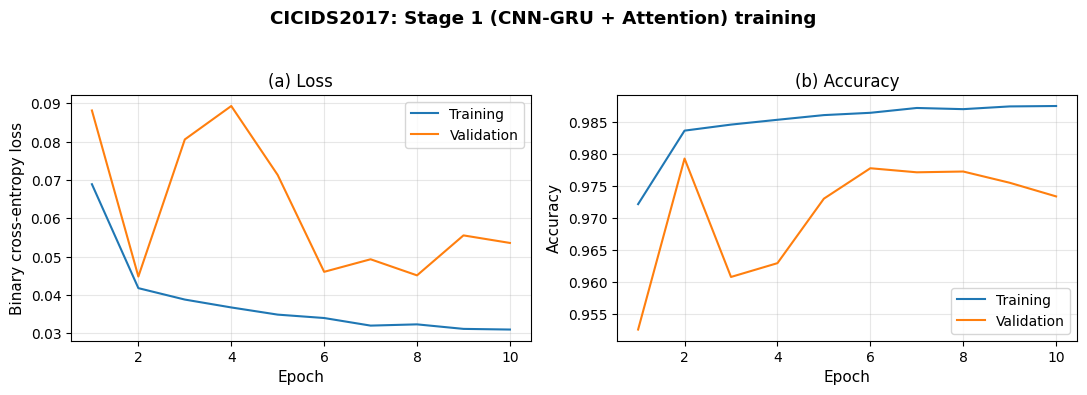

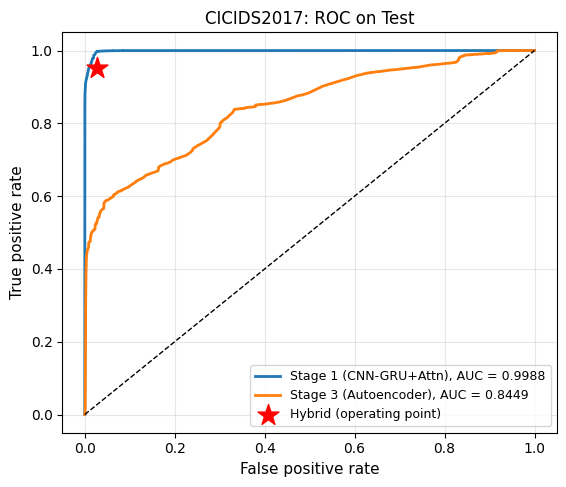

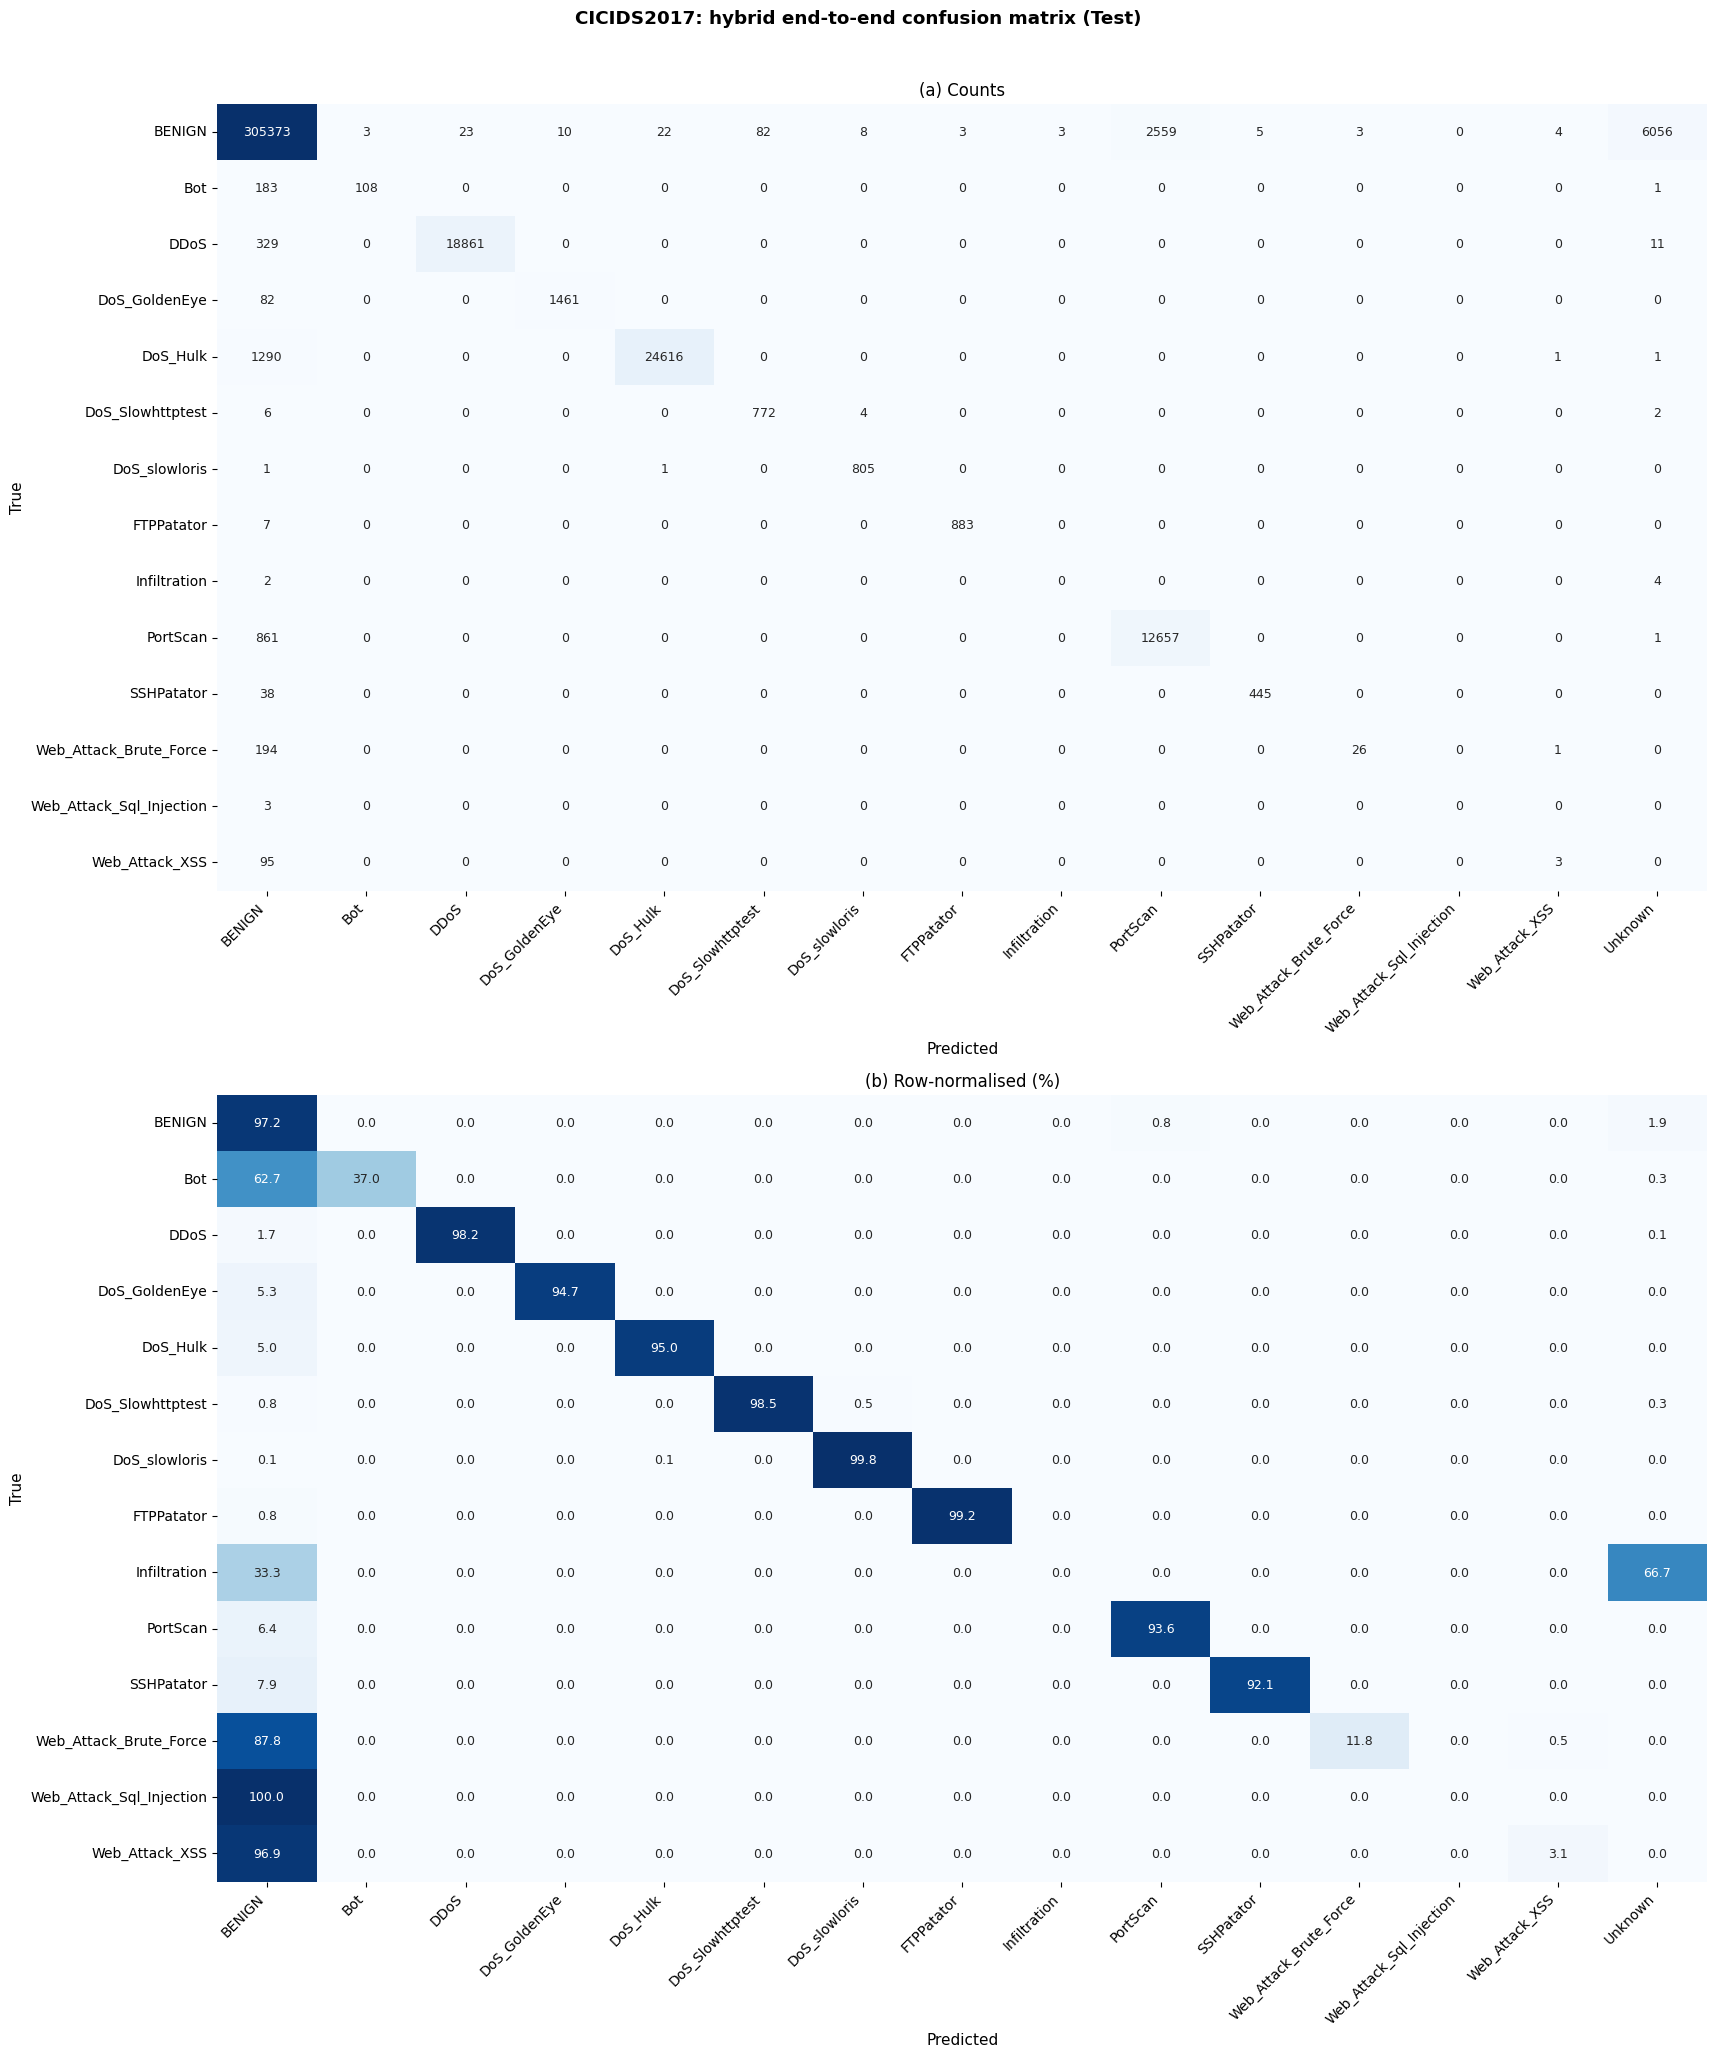

 AE budget (val FPR)  Threshold  Detection rate    FAR  Operating point
               0.005     0.6113          0.9514 0.0134            False
               0.010     0.3636          0.9514 0.0186            False
               0.020     0.2218          0.9515 0.0280             True
               0.030     0.1511          0.9515 0.0380            False
               0.050     0.0964          0.9517 0.0578            False
               0.075     0.0617          0.9519 0.0830            False
               0.100     0.0445          0.9521 0.1072            False


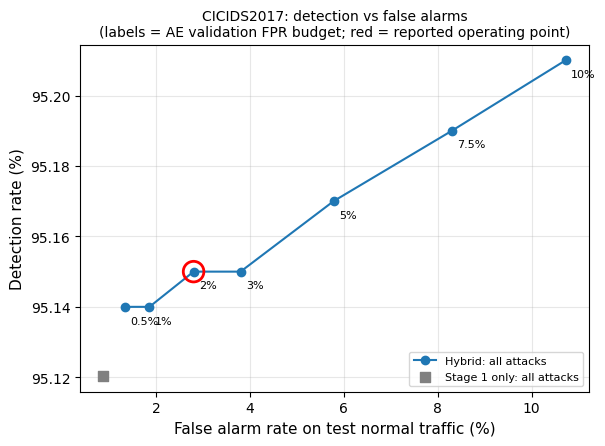

In [19]:
if 'CICIDS2017' in DATASETS_TO_RUN:
    paper_figures('CICIDS2017', run_cic, 'Test', NORMAL_CIC)
    tradeoff_curve('CICIDS2017', run_cic, CIC, 'Test', NORMAL_CIC)
    save_all()

### CICIDS2017 — zero-day simulation (leave-one-attack-out)

For each selected attack class, all its samples are removed from training and validation; Stage 1 and Stage 2 are retrained and the Autoencoder (trained on normal traffic only) is reused. We measure how much of the **unseen** class is still detected.

In [20]:
if 'CICIDS2017' in DATASETS_TO_RUN:
    Xte, cte = CIC['tests']['Test']
    if CIC_ZERO_DAY_CLASSES is None:
        vc = pd.Series(cte[cte != NORMAL_CIC]).value_counts()
        elig = list(vc[vc >= 100].index[::-1])            # ascending by size
        CIC_ZERO_DAY_CLASSES = sorted({elig[0], elig[len(elig) // 2], elig[-1]}) if elig else []
    print('Leave-one-attack-out classes:', CIC_ZERO_DAY_CLASSES)

    nrm = cte == NORMAL_CIC
    ae_det = run_cic['s3'].predict(Xte).astype(bool)
    for held in CIC_ZERO_DAY_CLASSES:
        mtr, mva = CIC['ctr'] != held, CIC['cval'] != held
        Dz = dict(Xtr=CIC['Xtr'][mtr], ctr=CIC['ctr'][mtr], Xval=CIC['Xval'][mva], cval=CIC['cval'][mva], tests={})
        r = run_pipeline(f'CICIDS2017 w/o {held}', Dz, normal=NORMAL_CIC, smote_target=SMOTE_TARGET_CIC,
                         batch=BATCH_CIC, epochs1=EPOCHS_ZERO_DAY, s3=run_cic['s3'], evaluate=False)
        out_, p1 = hybrid_predict(r['s1'], r['s2'], r['s3'], Xte, NORMAL_CIC)
        unseen = cte == held
        for nm, det in [('Proposed: Stage 1 CNN-GRU+Attn', p1 >= r['s1'].threshold),
                        ('Proposed: Stage 3 Autoencoder', ae_det), ('Proposed: Hybrid', out_ != NORMAL_CIC)]:
            add_zero_day('CICIDS2017', held, nm, det, unseen, nrm)
        del r; tf.keras.backend.clear_session()

        if CIC_LOAO_BASELINES:
            ytr_z, yval_z = (Dz['ctr'] != NORMAL_CIC).astype(int), (Dz['cval'] != NORMAL_CIC).astype(int)
            print(f'--- w/o {held}: Baseline XGBoost')
            Xs, ys = smote_binary(Dz['Xtr'], ytr_z)
            xgb = XGBClassifier(n_estimators=500, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                                tree_method='hist', device=XGB_DEVICE, random_state=SEED, n_jobs=-1, verbosity=0)
            xgb.fit(Xs, ys); del Xs, ys
            thr = best_f1_threshold(yval_z, xgb.predict_proba(Dz['Xval'])[:, 1])
            xgb_det = xgb.predict_proba(Xte)[:, 1] >= thr
            print(f'--- w/o {held}: Baseline GRU')
            gru = Stage1(EPOCHS_ZERO_DAY, BATCH_CIC, 'gru').fit(Dz['Xtr'], ytr_z, Dz['Xval'], yval_z)
            gru_det = gru.predict_proba(Xte) >= gru.threshold
            for nm, det in [('Baseline: XGBoost', xgb_det), ('Baseline: XGBoost + AE', xgb_det | ae_det),
                            ('Baseline: GRU', gru_det), ('Baseline: GRU + AE', gru_det | ae_det)]:
                add_zero_day('CICIDS2017', held, nm, det, unseen, nrm)
            del xgb, gru; tf.keras.backend.clear_session()
        save_all()
    print(pd.DataFrame([z for z in ZERO_DAY if z['Dataset'] == 'CICIDS2017']).to_string(index=False))

Leave-one-attack-out classes: ['DoS_Hulk', 'FTPPatator', 'Web_Attack_Brute_Force']

=== CICIDS2017 w/o DoS_Hulk: Stage 1 (CNN-GRU+Attn) ===
Epoch 1/10
2864/2864 - 194s - 68ms/step - accuracy: 0.9778 - loss: 0.0618 - val_accuracy: 0.9752 - val_loss: 0.0519 - learning_rate: 0.0010
Epoch 2/10
2864/2864 - 194s - 68ms/step - accuracy: 0.9851 - loss: 0.0421 - val_accuracy: 0.9739 - val_loss: 0.0577 - learning_rate: 0.0010
Epoch 3/10
2864/2864 - 195s - 68ms/step - accuracy: 0.9861 - loss: 0.0395 - val_accuracy: 0.9796 - val_loss: 0.0446 - learning_rate: 0.0010
Epoch 4/10
2864/2864 - 195s - 68ms/step - accuracy: 0.9867 - loss: 0.0379 - val_accuracy: 0.9802 - val_loss: 0.0431 - learning_rate: 0.0010
Epoch 5/10
2864/2864 - 195s - 68ms/step - accuracy: 0.9871 - loss: 0.0368 - val_accuracy: 0.9800 - val_loss: 0.0419 - learning_rate: 0.0010
Epoch 6/10
2864/2864 - 195s - 68ms/step - accuracy: 0.9872 - loss: 0.0361 - val_accuracy: 0.9800 - val_loss: 0.0443 - learning_rate: 0.0010
Epoch 7/10
2864/2864

## Part C — Baselines, ablation, multiple seeds, significance, explainability

Every model uses **the same splits, preprocessing, SMOTE on the training split only, and a validation-selected threshold** as the proposed Stage 1, so the comparison is fair. Results are saved after every block.

In [21]:
if RUN_PART_C:
    from sklearn.linear_model import LogisticRegression
    from sklearn.svm import LinearSVC
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import RandomForestClassifier
    from scipy.stats import chi2 as chi2_dist

    EXP = {}
    if 'NSL-KDD' in RUNS:
        EXP['NSL-KDD'] = dict(D=KDD, normal='Normal', split='KDDTest+', run=run_kdd, batch=BATCH_KDD,
                              epochs=EPOCHS_STAGE1, arch_ablation=True,
                              smote=SMOTE_TARGET_KDD, novel=KDD_NOVEL, feat_names=KDD_FEATURES,
                              zd_name=f'{len(novel)} novel types in KDDTest+')
    if 'CICIDS2017' in RUNS:
        EXP['CICIDS2017'] = dict(D=CIC, normal=NORMAL_CIC, split='Test', run=run_cic, batch=BATCH_CIC,
                                 epochs=EPOCHS_STAGE1_CIC, arch_ablation=CIC_ARCH_ABLATION,
                                 smote=SMOTE_TARGET_CIC, novel=None, feat_names=CIC_FEATURES, zd_name=None)

    def eval_detector(ds, model_name, score_fn, thr):
        info = EXP[ds]
        X, c = info['D']['tests'][info['split']]
        y = (c != info['normal']).astype(int)
        t = time.time(); s = score_fn(X); t_inf = time.time() - t
        pred = (s >= thr).astype(int)
        log(ds, model_name, info['split'], bin_metrics(y, pred, s))
        PREDS[(ds, model_name)], SCORES[(ds, model_name)] = pred, s
        if info['novel'] is not None:
            add_zero_day(ds, info['zd_name'], model_name, pred.astype(bool), info['novel'], y == 0)
        return 1000 * t_inf / len(X)

    for ds, info in EXP.items():          # reference predictions of the proposed system
        P = info['run']['preds'][info['split']]
        PREDS[(ds, 'Proposed: Stage 1 CNN-GRU+Attn')] = (P['p1'] >= info['run']['s1'].threshold).astype(int)
        SCORES[(ds, 'Proposed: Stage 1 CNN-GRU+Attn')] = P['p1']
        PREDS[(ds, 'Proposed: Hybrid')] = (P['out'] != info['normal']).astype(int)
    print('Part C datasets:', list(EXP))

Part C datasets: ['CICIDS2017']


### C1 — Classical machine-learning baselines (binary detection)

In [22]:
if RUN_PART_C:
    def classical_models():
        return {
            'Baseline: Logistic Regression': LogisticRegression(max_iter=1000),
            'Baseline: Linear SVM':          LinearSVC(dual=False, max_iter=2000),
            'Baseline: Decision Tree':       DecisionTreeClassifier(random_state=SEED),
            'Baseline: Random Forest':       RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
            'Baseline: XGBoost':             XGBClassifier(n_estimators=500, max_depth=8, learning_rate=0.1,
                                                 subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                                                 device=XGB_DEVICE, random_state=SEED, n_jobs=-1, verbosity=0),
        }

    def model_score(m, X):
        return m.predict_proba(X)[:, 1] if hasattr(m, 'predict_proba') else m.decision_function(X)

    for ds, info in EXP.items():
        D, normal = info['D'], info['normal']
        ytr, yval = (D['ctr'] != normal).astype(int), (D['cval'] != normal).astype(int)
        Xs, ys = smote_binary(D['Xtr'], ytr)
        for name, m in classical_models().items():
            print(f'\n--- {ds}: {name}')
            t = time.time(); m.fit(Xs, ys); t_tr = time.time() - t
            thr = best_f1_threshold(yval, model_score(m, D['Xval']))
            ms = eval_detector(ds, name, lambda X, m=m: model_score(m, X), thr)
            upsert(BASE_COSTS, {'Dataset': ds, 'Model': name, 'Params': None, 'Train (s)': round(t_tr, 1),
                                'Infer (ms/sample)': round(ms, 4)}, ['Dataset', 'Model'])
        del Xs, ys
        save_all()


--- CICIDS2017: Baseline: Logistic Regression
  [CICIDS2017 | Test] Baseline: Logistic Regression: Acc=96.01% Prec=83.85% Rec=94.55% F1=88.88% FAR=3.70% MCC=86.69% AUC=0.9879

--- CICIDS2017: Baseline: Linear SVM
  [CICIDS2017 | Test] Baseline: Linear SVM: Acc=95.96% Prec=83.56% Rec=94.68% F1=88.77% FAR=3.78% MCC=86.57% AUC=0.9858

--- CICIDS2017: Baseline: Decision Tree
  [CICIDS2017 | Test] Baseline: Decision Tree: Acc=99.91% Prec=99.69% Rec=99.81% F1=99.75% FAR=0.06% MCC=99.70% AUC=0.9987

--- CICIDS2017: Baseline: Random Forest
  [CICIDS2017 | Test] Baseline: Random Forest: Acc=99.91% Prec=99.64% Rec=99.84% F1=99.74% FAR=0.07% MCC=99.69% AUC=0.9999

--- CICIDS2017: Baseline: XGBoost
  [CICIDS2017 | Test] Baseline: XGBoost: Acc=99.94% Prec=99.80% Rec=99.86% F1=99.83% FAR=0.04% MCC=99.80% AUC=1.0000


### C2 — Deep-learning baselines and architecture ablation (Stage 1)

| Name | Description |
|---|---|
| Baseline: CNN / LSTM / GRU | Standard single-family deep models |
| Ablation: w/o Attention | CNN + GRU, no attention |
| Ablation: w/o CNN | GRU + Attention |
| Ablation: w/o GRU | CNN + Attention |
| Ablation: w/o SMOTE | Proposed model with class weights instead of SMOTE |

In [23]:
if RUN_PART_C:
    ARCH_RUNS = [('Baseline: CNN', 'cnn', True), ('Baseline: LSTM', 'lstm', True), ('Baseline: GRU', 'gru', True),
                 ('Ablation: w/o Attention', 'no_attention', True), ('Ablation: w/o CNN', 'no_cnn', True),
                 ('Ablation: w/o GRU', 'no_gru', True), ('Ablation: w/o SMOTE', 'proposed', False)]

    for ds, info in EXP.items():
        D, normal = info['D'], info['normal']
        ytr, yval = (D['ctr'] != normal).astype(int), (D['cval'] != normal).astype(int)
        for name, arch, smote_on in ARCH_RUNS:
            if name.startswith('Ablation') and not info['arch_ablation']:
                continue
            print(f'\n--- {ds}: {name}')
            USE_SMOTE = smote_on
            try:
                m = Stage1(info['epochs'], info['batch'], arch).fit(D['Xtr'], ytr, D['Xval'], yval)
            finally:
                USE_SMOTE = True
            ms = eval_detector(ds, name, m.predict_proba, m.threshold)
            upsert(BASE_COSTS, {'Dataset': ds, 'Model': name, 'Params': m.n_params,
                                'Train (s)': round(m.train_time, 1), 'Infer (ms/sample)': round(ms, 4)},
                   ['Dataset', 'Model'])
            del m; tf.keras.backend.clear_session()
            save_all()


--- CICIDS2017: Baseline: CNN
Epoch 1/20
2864/2864 - 37s - 13ms/step - accuracy: 0.9551 - loss: 0.1108 - val_accuracy: 0.9323 - val_loss: 0.1793 - learning_rate: 0.0010
Epoch 2/20
2864/2864 - 24s - 9ms/step - accuracy: 0.9715 - loss: 0.0706 - val_accuracy: 0.8423 - val_loss: 0.3552 - learning_rate: 0.0010
Epoch 3/20
2864/2864 - 25s - 9ms/step - accuracy: 0.9780 - loss: 0.0567 - val_accuracy: 0.8463 - val_loss: 0.5183 - learning_rate: 0.0010
Epoch 4/20
2864/2864 - 25s - 9ms/step - accuracy: 0.9804 - loss: 0.0508 - val_accuracy: 0.8309 - val_loss: 1.0865 - learning_rate: 0.0010
Epoch 5/20
2864/2864 - 25s - 9ms/step - accuracy: 0.9812 - loss: 0.0482 - val_accuracy: 0.8192 - val_loss: 0.4482 - learning_rate: 0.0010
Epoch 6/20
2864/2864 - 25s - 9ms/step - accuracy: 0.9824 - loss: 0.0447 - val_accuracy: 0.7299 - val_loss: 0.5587 - learning_rate: 5.0000e-04
Epoch 7/20
2864/2864 - 25s - 9ms/step - accuracy: 0.9828 - loss: 0.0435 - val_accuracy: 0.8142 - val_loss: 0.5410 - learning_rate: 5.000

### C3 — Pipeline ablation (what each stage contributes; no retraining)

In [24]:
if RUN_PART_C:
    VARIANTS = [('Pipeline: Stage 1 + 2',               False, 0.0),
                ('Pipeline: Stage 1 + 2 + confidence',  False, CONF_T),
                ('Pipeline: Stage 1 + 2 + 3 (AE)',      True,  0.0),
                ('Pipeline: Full hybrid',               True,  CONF_T)]

    for ds, info in EXP.items():
        r, normal = info['run'], info['normal']
        X, c = info['D']['tests'][info['split']]
        P = r['preds'][info['split']]
        y = (c != normal).astype(int)
        labels = sorted(set(c.astype(str)))
        for name, use_ae, ct in VARIANTS:
            out_, _ = hybrid_predict(r['s1'], r['s2'], r['s3'], X, normal, use_ae=use_ae, conf_t=ct,
                                     p1=P['p1'], e3=P['e3'])
            pred = (out_ != normal).astype(int)
            log(ds, name + ' [binary]', info['split'], bin_metrics(y, pred))
            log(ds, name + ' [multiclass, strict]', info['split'], multi_metrics(c, out_, labels=labels))
            log(ds, name + ' [detection-aware]', info['split'], detection_aware(c, out_, normal))
            if info['novel'] is not None:
                add_zero_day(ds, info['zd_name'], name, pred.astype(bool), info['novel'], y == 0)
    save_all()

  [CICIDS2017 | Test] Pipeline: Stage 1 + 2 [binary]: Acc=98.45% Prec=95.67% Rec=95.12% F1=95.39% FAR=0.87% MCC=94.46%
  [CICIDS2017 | Test] Pipeline: Stage 1 + 2 [multiclass, strict]: Acc=98.45% MacroF1=67.72% WeightedF1=98.43% MCC=94.83%
  [CICIDS2017 | Test] Pipeline: Stage 1 + 2 [detection-aware]: DA_Acc=98.45% DetRate=95.12% ExactType=95.11% UnknownShare=0.00% UnknownPrec=0.00%
  [CICIDS2017 | Test] Pipeline: Stage 1 + 2 + confidence [binary]: Acc=98.45% Prec=95.67% Rec=95.12% F1=95.39% FAR=0.87% MCC=94.46%
  [CICIDS2017 | Test] Pipeline: Stage 1 + 2 + confidence [multiclass, strict]: Acc=98.45% MacroF1=67.77% WeightedF1=98.43% MCC=94.83%
  [CICIDS2017 | Test] Pipeline: Stage 1 + 2 + confidence [detection-aware]: DA_Acc=98.45% DetRate=95.12% ExactType=95.11% UnknownShare=0.00% UnknownPrec=0.00%
  [CICIDS2017 | Test] Pipeline: Stage 1 + 2 + 3 (AE) [binary]: Acc=96.86% Prec=87.36% Rec=95.15% F1=91.09% FAR=2.80% MCC=89.30%
  [CICIDS2017 | Test] Pipeline: Stage 1 + 2 + 3 (AE) [multicl

### C3b — Is the Autoencoder stage useful with other Stage-1 detectors? (baseline + AE, no retraining)

The Autoencoder flags samples that the supervised detector calls normal. Here it is attached to the strongest baselines, so the contribution of the anomaly stage can be separated from the choice of Stage-1 model.

In [25]:
if RUN_PART_C:
    for ds, info in EXP.items():
        P = info['run']['preds'][info['split']]
        ae_flag = P['e3'] > info['run']['s3'].threshold
        for base in ['Baseline: XGBoost', 'Baseline: Random Forest', 'Baseline: GRU']:
            if (ds, base) not in PREDS:
                continue
            pred = (PREDS[(ds, base)].astype(bool) | ae_flag).astype(int)
            name = base + ' + AE'
            log(ds, name, info['split'], bin_metrics(P['y'], pred))
            PREDS[(ds, name)] = pred
            if info['novel'] is not None:
                add_zero_day(ds, info['zd_name'], name, pred.astype(bool), info['novel'], P['y'] == 0)
    save_all()

  [CICIDS2017 | Test] Baseline: XGBoost + AE: Acc=98.32% Prec=91.05% Rec=99.87% F1=95.25% FAR=1.99% MCC=94.38%
  [CICIDS2017 | Test] Baseline: Random Forest + AE: Acc=98.29% Prec=90.91% Rec=99.84% F1=95.17% FAR=2.03% MCC=94.28%
  [CICIDS2017 | Test] Baseline: GRU + AE: Acc=97.32% Prec=88.44% Rec=96.75% F1=92.41% FAR=2.57% MCC=90.91%


### C4 — Multiple random seeds (mean ± std)

The data split is fixed; model initialisation, SMOTE and XGBoost randomness change with the seed. All three stages are retrained for every seed.

In [26]:
if RUN_PART_C:
    def seed_metrics(ds, sd, r):
        info = EXP[ds]; normal = info['normal']
        X, c = info['D']['tests'][info['split']]
        y = (c != normal).astype(int)
        p1 = r['s1'].predict_proba(X)
        out_, _ = hybrid_predict(r['s1'], r['s2'], r['s3'], X, normal, p1=p1)
        s1d, hyd = p1 >= r['s1'].threshold, out_ != normal
        rows = [('Stage 1 CNN-GRU+Attn (binary)', bin_metrics(y, s1d.astype(int), p1), s1d),
                ('Hybrid (binary)', bin_metrics(y, hyd.astype(int)), hyd),
                ('Hybrid (multiclass, strict)', multi_metrics(c, out_, labels=sorted(set(c.astype(str)))), None),
                ('Hybrid (detection-aware)', detection_aware(c, out_, normal), None)]
        for model, d, det in rows:
            if info['novel'] is not None and det is not None:
                d = {**d, 'ZeroDayDR': float(det[info['novel']].mean())}
            upsert(SEED_RUNS, {'Dataset': ds, 'Model': model, 'Seed': sd, **d}, ['Dataset', 'Model', 'Seed'])

    for ds, info in EXP.items():
        for sd in (SEEDS_KDD if ds == 'NSL-KDD' else SEEDS_CIC):
            print(f'\n##### {ds} | seed {sd}')
            SEED = sd
            if sd == MAIN_SEED:
                r = info['run']
            else:
                r = run_pipeline(f'{ds} seed {sd}', info['D'], info['normal'], info['smote'], info['batch'],
                                 epochs1=info['epochs'], evaluate=False)
            seed_metrics(ds, sd, r)
            if r is not info['run']:
                del r; tf.keras.backend.clear_session()
            save_all()
    SEED = MAIN_SEED

    sr = pd.DataFrame(SEED_RUNS)
    mcols = [c for c in sr.columns if c not in ('Dataset', 'Model', 'Seed')]
    agg = sr.groupby(['Dataset', 'Model'], sort=False)[mcols].agg(['mean', 'std'])
    TABLES['results_seeds_summary'] = pd.DataFrame(
        {m: (agg[(m, 'mean')] * 100).map('{:.2f}'.format) + ' ± ' + (agg[(m, 'std')] * 100).map('{:.2f}'.format)
         for m in mcols if agg[(m, 'mean')].notna().any()}).replace('nan ± nan', '').reset_index()
    TABLES['results_seeds_summary'].insert(2, 'Seeds', sr.groupby(['Dataset', 'Model'], sort=False).size().values)
    print(TABLES['results_seeds_summary'].to_string(index=False))
    save_all()


##### CICIDS2017 | seed 42

##### CICIDS2017 | seed 7

=== CICIDS2017 seed 7: Stage 1 (CNN-GRU+Attn) ===
Epoch 1/20
2864/2864 - 193s - 67ms/step - accuracy: 0.9714 - loss: 0.0703 - val_accuracy: 0.9754 - val_loss: 0.0501 - learning_rate: 0.0010
Epoch 2/20
2864/2864 - 192s - 67ms/step - accuracy: 0.9828 - loss: 0.0442 - val_accuracy: 0.9798 - val_loss: 0.0388 - learning_rate: 0.0010
Epoch 3/20
2864/2864 - 193s - 67ms/step - accuracy: 0.9845 - loss: 0.0391 - val_accuracy: 0.9762 - val_loss: 0.0445 - learning_rate: 0.0010
Epoch 4/20
2864/2864 - 193s - 67ms/step - accuracy: 0.9851 - loss: 0.0374 - val_accuracy: 0.9788 - val_loss: 0.0387 - learning_rate: 0.0010
Epoch 5/20
2864/2864 - 192s - 67ms/step - accuracy: 0.9855 - loss: 0.0364 - val_accuracy: 0.9786 - val_loss: 0.0383 - learning_rate: 0.0010
Epoch 6/20
2864/2864 - 192s - 67ms/step - accuracy: 0.9859 - loss: 0.0354 - val_accuracy: 0.9777 - val_loss: 0.0424 - learning_rate: 0.0010
Epoch 7/20
2864/2864 - 192s - 67ms/step - accuracy: 0.

### C5 — McNemar test (proposed hybrid vs every other model, binary predictions on the main test set)

In [27]:
if RUN_PART_C:
    def mcnemar(y, a, b):
        ca, cb = a == y, b == y
        n01, n10 = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))
        stat = (abs(n01 - n10) - 1) ** 2 / (n01 + n10) if (n01 + n10) else 0.0
        return n01, n10, stat, float(chi2_dist.sf(stat, 1))

    MCNEMAR.clear()
    for ds, info in EXP.items():
        X, c = info['D']['tests'][info['split']]
        y = (c != info['normal']).astype(int)
        ref = PREDS[(ds, 'Proposed: Hybrid')]
        for (d2, name), pred in PREDS.items():
            if d2 != ds or name == 'Proposed: Hybrid':
                continue
            n01, n10, stat, p = mcnemar(y, ref, pred)
            MCNEMAR.append({'Dataset': ds, 'Compared with': name,
                            'Hybrid right / other wrong': n01, 'Hybrid wrong / other right': n10,
                            'Chi2': round(stat, 3), 'p-value': p, 'Significant (p<0.05)': p < 0.05,
                            'Better': 'Hybrid' if n01 > n10 else name})
    print(pd.DataFrame(MCNEMAR).to_string(index=False))
    save_all()

   Dataset                  Compared with  Hybrid right / other wrong  Hybrid wrong / other right      Chi2       p-value  Significant (p<0.05)                         Better
CICIDS2017 Proposed: Stage 1 CNN-GRU+Attn                          20                        6034  5972.278  0.000000e+00                  True Proposed: Stage 1 CNN-GRU+Attn
CICIDS2017  Baseline: Logistic Regression                        9808                        6592   630.258 4.393301e-139                  True                         Hybrid
CICIDS2017           Baseline: Linear SVM                       10656                        7260   643.337 6.283508e-142                  True                         Hybrid
CICIDS2017        Baseline: Decision Tree                         188                       11738 11183.918  0.000000e+00                  True        Baseline: Decision Tree
CICIDS2017        Baseline: Random Forest                         206                       11745 11139.272  0.000000e+00    

### C6 — SHAP explanation of Stage 2 (XGBoost)

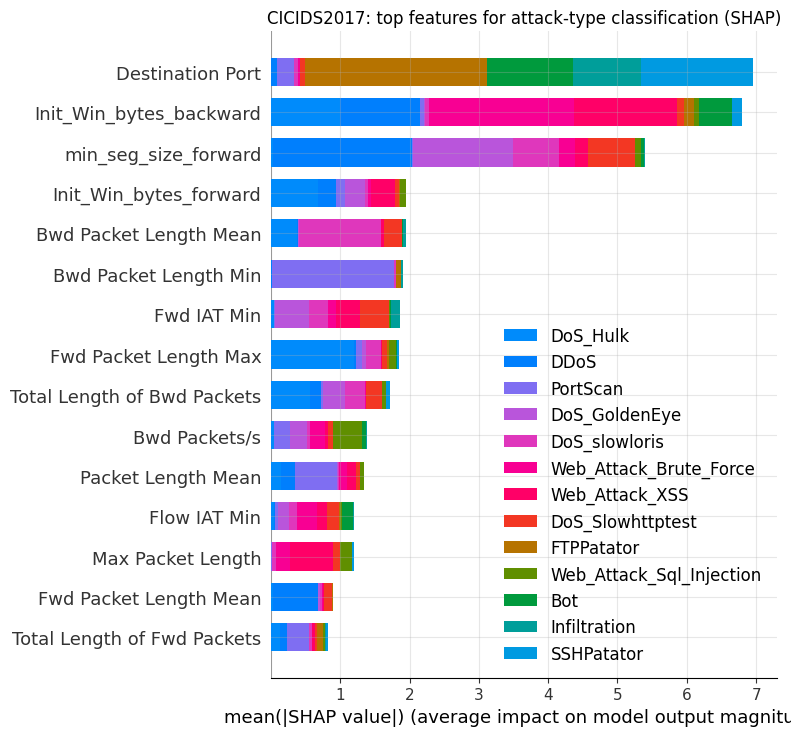

In [28]:
if RUN_PART_C:
    try:
        import shap
        for ds, info in EXP.items():
            s2, normal = info['run']['s2'], info['normal']
            X, c = info['D']['tests'][info['split']]
            m = np.where((c != normal) & np.isin(c, s2.le.classes_))[0]
            m = np.random.default_rng(SEED).choice(m, size=min(2000, len(m)), replace=False)
            s2.model.set_params(device='cpu')
            sv = shap.TreeExplainer(s2.model).shap_values(X[m])
            if isinstance(sv, np.ndarray) and sv.ndim == 3:
                sv = [sv[:, :, k] for k in range(sv.shape[2])]
            plt.figure()
            shap.summary_plot(sv, X[m], feature_names=list(info['feat_names']),
                              class_names=list(s2.le.classes_), plot_type='bar', max_display=15, show=False)
            plt.title(f'{ds}: top features for attack-type classification (SHAP)')
            plt.tight_layout(); savefig(f'{tag_of(ds)}_fig_shap'); plt.show()
            s2.model.set_params(device=XGB_DEVICE)
    except Exception as e:
        print('SHAP skipped:', repr(e))

## Final results — paper tables and comparison figures

All tables are saved as CSV (and LaTeX, `.tex`) in the run folder; all figures as PNG (300 dpi) and PDF.

In [29]:
pd.set_option('display.width', 250, 'display.max_columns', 30)
res = pd.DataFrame(RESULTS)
MAIN_SPLIT = {'NSL-KDD': 'KDDTest+', 'CICIDS2017': 'Test'}
on_main = res.apply(lambda r: r['Split'] == MAIN_SPLIT.get(r['Dataset']), axis=1) if len(res) else []

def section(title):
    print('\n' + '=' * 110 + f'\n  {title}\n' + '=' * 110)

def export(key, df):
    TABLES[key] = df
    try:
        (df.drop(columns=['Dataset']) if 'Dataset' in df else df).to_latex(
            out(f'{key}.tex'), index=False, float_format='%.2f')
    except Exception:
        pass
    print(df.to_string(index=False))

pct = lambda df, cols: df.assign(**{c: (df[c] * 100).round(2) for c in cols if c in df})

# T1: binary detection comparison
bin_models = ['Proposed: Hybrid (binary)', 'Proposed: Stage 1 CNN-GRU+Attn', 'Proposed: Stage 3 Autoencoder'] + \
             [m for m in res['Model'].unique() if m.startswith('Baseline:')]   # includes 'Baseline: X + AE'
t1 = res[on_main & res['Model'].isin(bin_models)][['Dataset', 'Model', 'Acc', 'Prec', 'Rec', 'F1', 'FAR', 'MCC', 'AUC']]
t1 = pct(t1, ['Acc', 'Prec', 'Rec', 'F1', 'FAR', 'MCC'])
section('T1  BINARY DETECTION — proposed vs baselines (main test set, %)'); export('table1_binary_comparison', t1)

# T2: multiclass + detection-aware
t2a = res[on_main & res['Model'].isin(['Proposed: Stage 2 XGBoost (known attacks)', 'Proposed: Hybrid (multiclass, strict)'])]
t2a = pct(t2a[['Dataset', 'Model', 'Acc', 'MacroF1', 'WeightedF1', 'MCC']], ['Acc', 'MacroF1', 'WeightedF1', 'MCC'])
section('T2a MULTICLASS (%)'); export('table2a_multiclass', t2a)
t2b = res[on_main & (res['Model'] == 'Proposed: Hybrid (detection-aware)')]
t2b = pct(t2b[['Dataset', 'DA_Acc', 'DetRate', 'ExactType', 'UnknownShare', 'UnknownPrec']],
          ['DA_Acc', 'DetRate', 'ExactType', 'UnknownShare', 'UnknownPrec'])
section('T2b HYBRID DETECTION-AWARE VIEW (%)'); export('table2b_detection_aware', t2b)

# T3: zero-day
t3 = pd.DataFrame(ZERO_DAY)
if len(t3):
    t3 = pct(t3, ['Detection rate', 'FAR on normal'])
section('T3  ZERO-DAY (UNSEEN ATTACK) DETECTION (%)'); export('table3_zero_day', t3)

# T4: ablation
t4 = res[on_main & (res['Model'].str.startswith('Ablation:') | (res['Model'] == 'Proposed: Stage 1 CNN-GRU+Attn'))]
t4 = pct(t4[['Dataset', 'Model', 'Acc', 'Prec', 'Rec', 'F1', 'FAR', 'MCC', 'AUC']], ['Acc', 'Prec', 'Rec', 'F1', 'FAR', 'MCC'])
section('T4a ARCHITECTURE ABLATION (Stage 1, %)'); export('table4a_ablation_architecture', t4)
t4b = res[on_main & res['Model'].str.startswith('Pipeline:')]
if len(t4b):
    keep = [c for c in ['Acc', 'Rec', 'FAR', 'F1', 'MacroF1', 'DA_Acc', 'DetRate', 'UnknownShare'] if c in t4b]
    t4b = pct(t4b[['Dataset', 'Model'] + keep], keep)
section('T4b PIPELINE ABLATION (%)'); export('table4b_ablation_pipeline', t4b)

# T5-T7
if 'results_seeds_summary' in TABLES:
    section('T5  MULTI-SEED (mean ± std, %)'); print(TABLES['results_seeds_summary'].to_string(index=False))
if MCNEMAR:
    section('T6  McNEMAR vs PROPOSED HYBRID'); print(pd.DataFrame(MCNEMAR).to_string(index=False))
section('T7  COMPUTATIONAL COST')
print(pd.DataFrame(COSTS).to_string(index=False)); print(pd.DataFrame(BASE_COSTS).to_string(index=False))
save_all()


  T1  BINARY DETECTION — proposed vs baselines (main test set, %)
   Dataset                          Model   Acc  Prec   Rec    F1  FAR   MCC    AUC
CICIDS2017 Proposed: Stage 1 CNN-GRU+Attn 98.45 95.67 95.12 95.39 0.87 94.46 0.9988
CICIDS2017  Proposed: Stage 3 Autoencoder 90.05 84.03 50.65 63.20 1.95 60.34 0.8449
CICIDS2017      Proposed: Hybrid (binary) 96.86 87.36 95.15 91.09 2.80 89.30    NaN
CICIDS2017  Baseline: Logistic Regression 96.01 83.85 94.55 88.88 3.70 86.69 0.9879
CICIDS2017           Baseline: Linear SVM 95.96 83.56 94.68 88.77 3.78 86.57 0.9858
CICIDS2017        Baseline: Decision Tree 99.91 99.69 99.81 99.75 0.06 99.70 0.9987
CICIDS2017        Baseline: Random Forest 99.91 99.64 99.84 99.74 0.07 99.69 0.9999
CICIDS2017              Baseline: XGBoost 99.94 99.80 99.86 99.83 0.04 99.80 1.0000
CICIDS2017                  Baseline: CNN 93.40 78.01 84.79 81.26 4.85 77.36 0.9744
CICIDS2017                 Baseline: LSTM 98.82 95.49 97.64 96.55 0.93 95.85 0.9993
CICIDS201

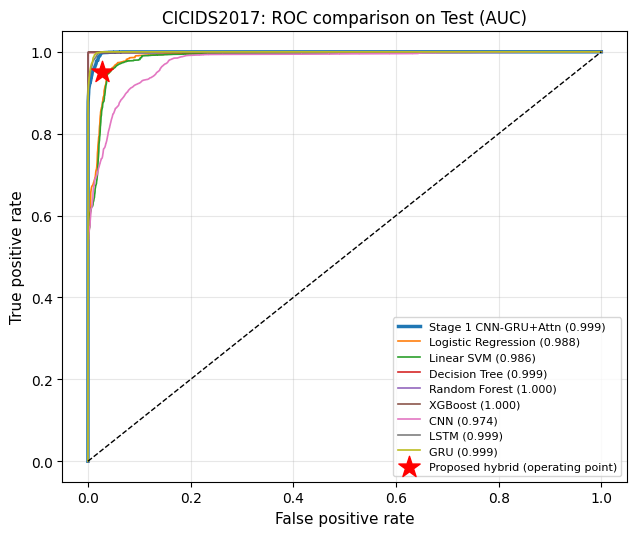

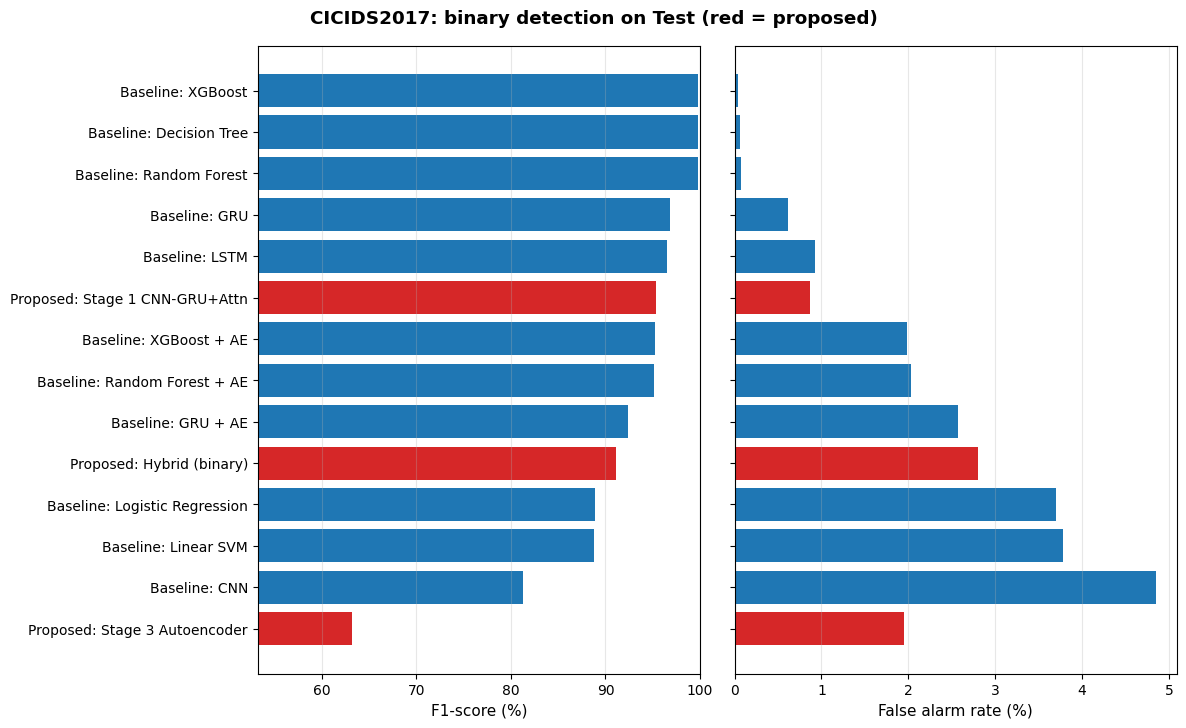


All outputs in: /kaggle/working/run_CICIDS2017
['cicids2017_class_distribution.csv', 'cicids2017_cleaning.csv', 'cicids2017_fig_comparison_bars.pdf', 'cicids2017_fig_comparison_bars.png', 'cicids2017_fig_confusion.pdf', 'cicids2017_fig_confusion.png', 'cicids2017_fig_roc.pdf', 'cicids2017_fig_roc.png', 'cicids2017_fig_roc_comparison.pdf', 'cicids2017_fig_roc_comparison.png', 'cicids2017_fig_shap.pdf', 'cicids2017_fig_shap.png', 'cicids2017_fig_tradeoff.pdf', 'cicids2017_fig_tradeoff.png', 'cicids2017_fig_training.pdf', 'cicids2017_fig_training.png', 'cicids2017_per_class_detection.csv', 'cicids2017_tradeoff.csv', 'results_all.csv', 'results_cost_baselines.csv', 'results_cost_proposed.csv', 'results_mcnemar.csv', 'results_seeds_raw.csv', 'results_seeds_summary.csv', 'results_zero_day.csv', 'table1_binary_comparison.csv', 'table1_binary_comparison.tex', 'table2a_multiclass.csv', 'table2a_multiclass.tex', 'table2b_detection_aware.csv', 'table2b_detection_aware.tex', 'table3_zero_day.csv'

In [30]:
# Comparison figures: ROC of all scored detectors, and F1 / FAR bars
for ds in [d for d in MAIN_SPLIT if d in RUNS]:
    info_run, split = RUNS[ds], MAIN_SPLIT[ds]
    P = info_run['preds'][split]
    normal = 'Normal' if ds == 'NSL-KDD' else NORMAL_CIC
    keys = [k for k in SCORES if k[0] == ds and not k[1].startswith('Ablation')]
    if keys:
        fig, ax = plt.subplots(figsize=(6.5, 5.5))
        for _, name in keys:
            s = SCORES[(ds, name)]
            fpr, tpr, _ = roc_curve(P['y'], s)
            ax.plot(fpr, tpr, lw=2.5 if name.startswith('Proposed') else 1.2,
                    label=f'{name.split(": ")[1]} ({roc_auc_score(P["y"], s):.3f})')
        hy = P['out'] != normal
        ax.scatter([hy[P['y'] == 0].mean()], [hy[P['y'] == 1].mean()], marker='*', s=260, color='red',
                   zorder=5, label='Proposed hybrid (operating point)')
        ax.plot([0, 1], [0, 1], 'k--', lw=1)
        ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
        ax.set_title(f'{ds}: ROC comparison on {split} (AUC)'); ax.legend(fontsize=8, loc='lower right')
        plt.tight_layout(); savefig(f'{tag_of(ds)}_fig_roc_comparison'); plt.show()

    t = res[(res['Dataset'] == ds) & (res['Split'] == split) & res['Model'].isin(bin_models)]
    if len(t) > 1:
        t = t.sort_values('F1')
        fig, ax = plt.subplots(1, 2, figsize=(12, 0.4 * len(t) + 1.8), sharey=True)
        col = ['tab:red' if m.startswith('Proposed') else 'tab:blue' for m in t['Model']]
        ax[0].barh(t['Model'], t['F1'] * 100, color=col); ax[0].set_xlabel('F1-score (%)')
        ax[0].set_xlim(max(0, t['F1'].min() * 100 - 10), 100)
        ax[1].barh(t['Model'], t['FAR'] * 100, color=col); ax[1].set_xlabel('False alarm rate (%)')
        for a in ax: a.grid(axis='y', alpha=0)
        fig.suptitle(f'{ds}: binary detection on {split} (red = proposed)', fontweight='bold')
        plt.tight_layout(); savefig(f'{tag_of(ds)}_fig_comparison_bars'); plt.show()

print('\nAll outputs in:', os.path.abspath(OUT_DIR))
print(sorted(os.listdir(OUT_DIR)))

## Download everything

In [31]:
import shutil
zip_path = shutil.make_archive(OUT_DIR, 'zip', OUT_DIR)
print('All outputs zipped ->', zip_path, f'({os.path.getsize(zip_path) / 1e6:.1f} MB)')
print('Download it from the Output tab (right panel, or the saved version page).')

All outputs zipped -> /kaggle/working/run_CICIDS2017.zip (2.1 MB)
Download it from the Output tab (right panel, or the saved version page).
